In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(STACAS)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

# Load dataset

In [ ]:
gut_cdn <- readRDS("../241201_VN_PREDICT2/data/cdn/gut_5p_integrated_cd4_prolif_filt.rds")

# Trajectory

In [7]:
library(grDevices)
library(RColorBrewer)
library(slingshot)

Loading required package: princurve

Loading required package: TrajectoryUtils

Loading required package: SingleCellExperiment



In [5]:
fun_basic <- gut_cdn

In [6]:
fun_basic

An object of class Seurat 
74985 features across 346456 samples within 5 assays 
Active assay: CollecTRI (769 features, 0 variable features)
 2 layers present: counts, data
 4 other assays present: RNA, integrated, RNA3, pathwayswmean
 2 dimensional reductions calculated: pca, umap

In [34]:
ls()

[1] "avgexp"                 "clone_table"            "ggtheme"               
[4] "gut_cdn"                "markers2"               "metadata_6"            
[7] "pct_expressing_boxplot" "sce"

In [7]:
Idents(fun_basic)  <- fun_basic$seurat_clusters

In [8]:
Idents(fun_basic)  %>% table

.
    8     1     6     7     3     9     5    11     4     2    10 
54392 51934 47505 44199 38339 31992 19573 18771 17587 11276 10888 

In [9]:
fun_basic@assays$integrated <- NULL

In [10]:
fun_basic@assays$RNA3 <- NULL

In [11]:
DefaultAssay(fun_basic) <- "RNA"


In [12]:
Idents(fun_basic) <- fun_basic$seurat_clusters

sce <- as.SingleCellExperiment(fun_basic)

reducedDim(sce, "PCA", withDimnames=TRUE) <- fun_basic[['pca']]@cell.embeddings
reducedDim(sce, "UMAP", withDimnames=TRUE) <- fun_basic[['umap']]@cell.embeddings

Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


Warning message in brewer.pal(11, "Blues"):
“n too large, allowed maximum for palette Blues is 9
Returning the palette you asked for with that many colors
”


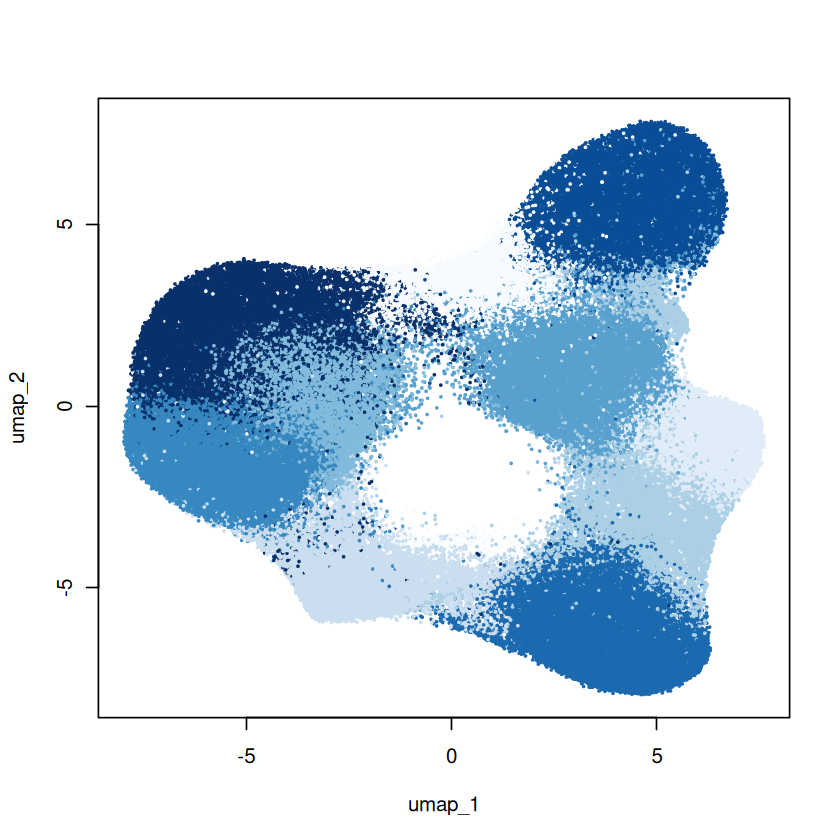

In [13]:
colors2 <- rev(colorRampPalette(brewer.pal(11,'Blues'))(10))
plot(reducedDims(sce)$UMAP, col = colors2[as.factor(sce$seurat_clusters)], pch = 16, cex = 0.3)


In [35]:
sce <- slingshot(sce, clusterLabels = 'seurat_clusters', reducedDim = 'UMAP', start.clus= '1', end.clus = '11')

In [ ]:
sce

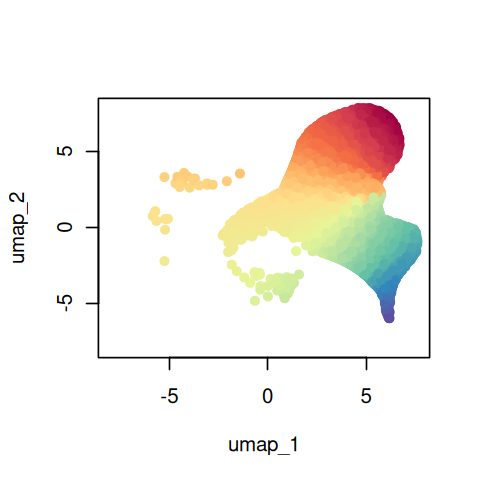

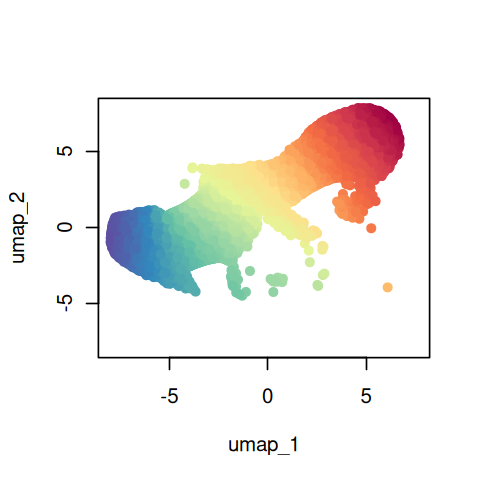

In [52]:
colors <- colorRampPalette(brewer.pal(11,'Spectral')[-6])(100)

options(repr.plot.width = 4, repr.plot.height = 4)
plot(reducedDims(sce)$UMAP, col = colors[cut(sce$slingPseudotime_1, breaks=100)], pch = 16)
plot(reducedDims(sce)$UMAP, col = colors[cut(sce$slingPseudotime_2, breaks=100)], pch = 16)

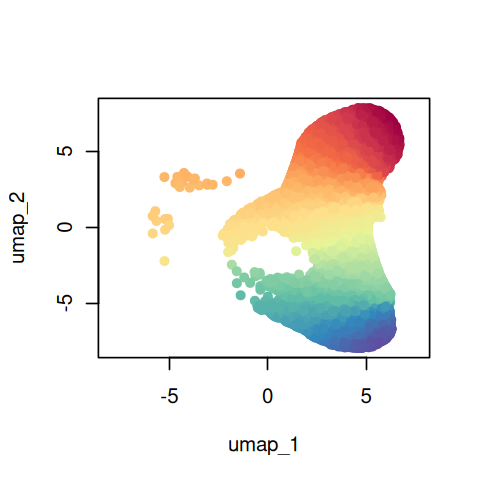

In [53]:
plot(reducedDims(sce)$UMAP, col = colors[cut(sce$slingPseudotime_3, breaks=100)], pch = 16)

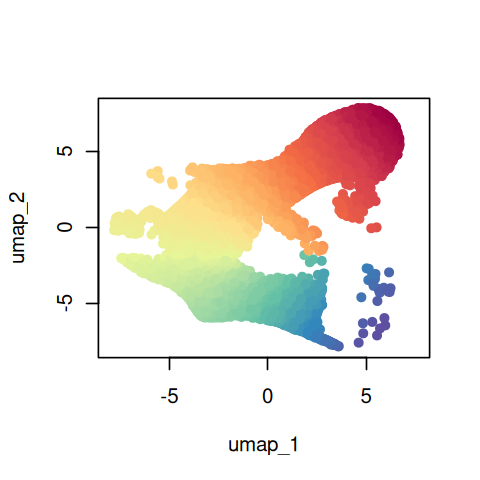

In [54]:
plot(reducedDims(sce)$UMAP, col = colors[cut(sce$slingPseudotime_4, breaks=100)], pch = 16)

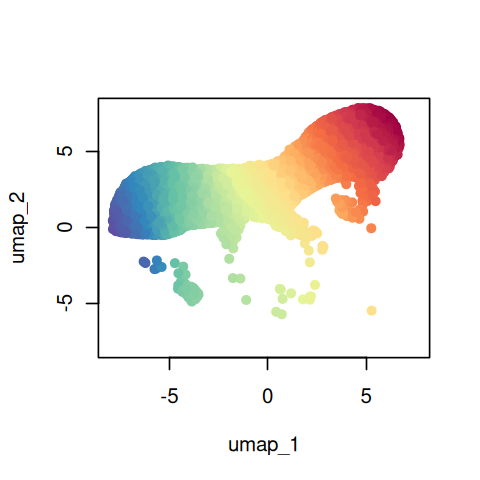

In [55]:
plot(reducedDims(sce)$UMAP, col = colors[cut(sce$slingPseudotime_5, breaks=100)], pch = 16)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



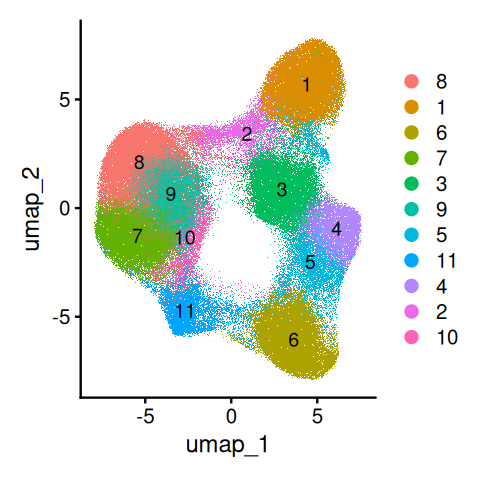

In [38]:
DimPlot(fun_basic, label = T)

In [47]:
lineages2 <- getLineages(data = reducedDims(sce)$UMAP, 
                         clusterLabels = sce$seurat_clusters, 
                         start.clus= c('1'), end.clus = '7')
lineages2 <- as.SlingshotDataSet(lineages2)

In [48]:
lineages2

class: SlingshotDataSet 

 Samples Dimensions
  346456          2

lineages: 5 
Lineage1: 1  2  3  5  4  
Lineage2: 1  2  9  10  7  
Lineage3: 1  2  3  5  6  
Lineage4: 1  2  9  10  11  
Lineage5: 1  2  9  8  

curves: 0 

In [49]:
curves <- getCurves(lineages2, approx_points = 300, thresh = 0.01, stretch = 0.8, allow.breaks = FALSE, shrink = 0.99)

In [51]:
curves

class: PseudotimeOrdering 
dim: 346456 5 
metadata(4): lineages mst slingParams curves
pathStats(2): pseudotime weights
cellnames(346456): AAACCTGAGAGCCTAG-1_1193610_1_1_1
  AAACCTGCAGTCACTA-1_1193610_1_1_1 ... CTCAGAATCAACGCTA-1_1542425_1_1_1
  GACGTTAAGTACGTTC-1_1542425_1_1_1
cellData names(2): reducedDim clusterLabels
pathnames(5): Lineage1 Lineage2 Lineage3 Lineage4 Lineage5
pathData names(0):

In [56]:
saveRDS(curves, "data/slingshot_curves.rds")

In [41]:
table(sce$seurat_clusters)


    8     1     6     7     3     9     5    11     4     2    10 
54392 51934 47505 44199 38339 31992 19573 18771 17587 11276 10888 

In [42]:
colors <- colorRampPalette(brewer.pal(11,'Spectral')[-6])(100)
dimred = reducedDims(sce)$UMAP
clustering = sce$seurat_clusters
pal = colors

In [ ]:
ls()

Warning message in brewer.pal(11, "Blues"):
“n too large, allowed maximum for palette Blues is 9
Returning the palette you asked for with that many colors
”


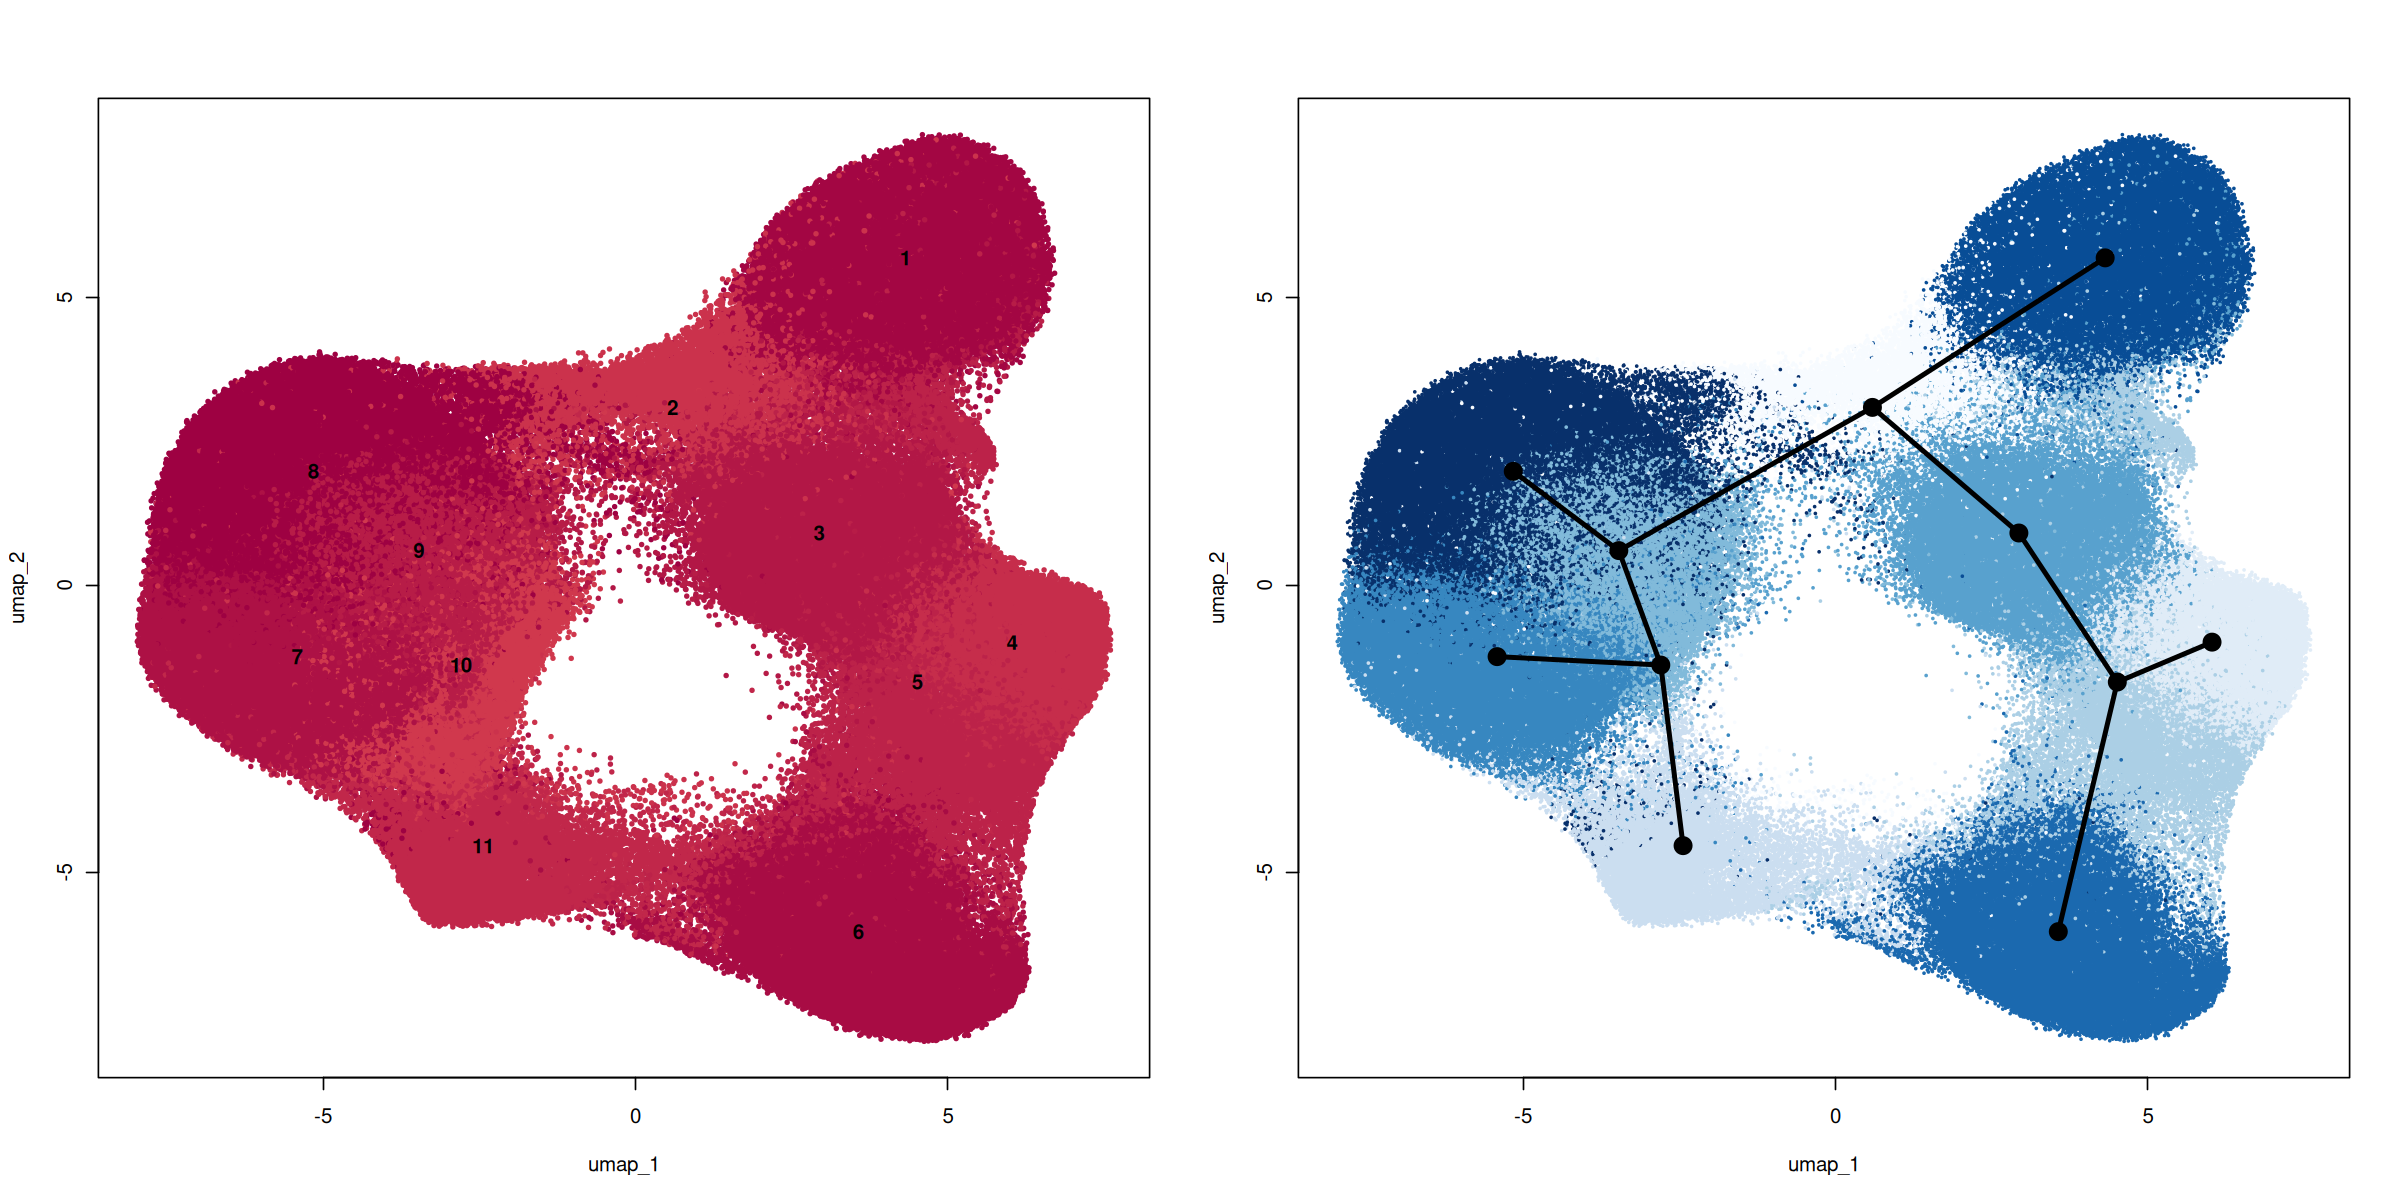

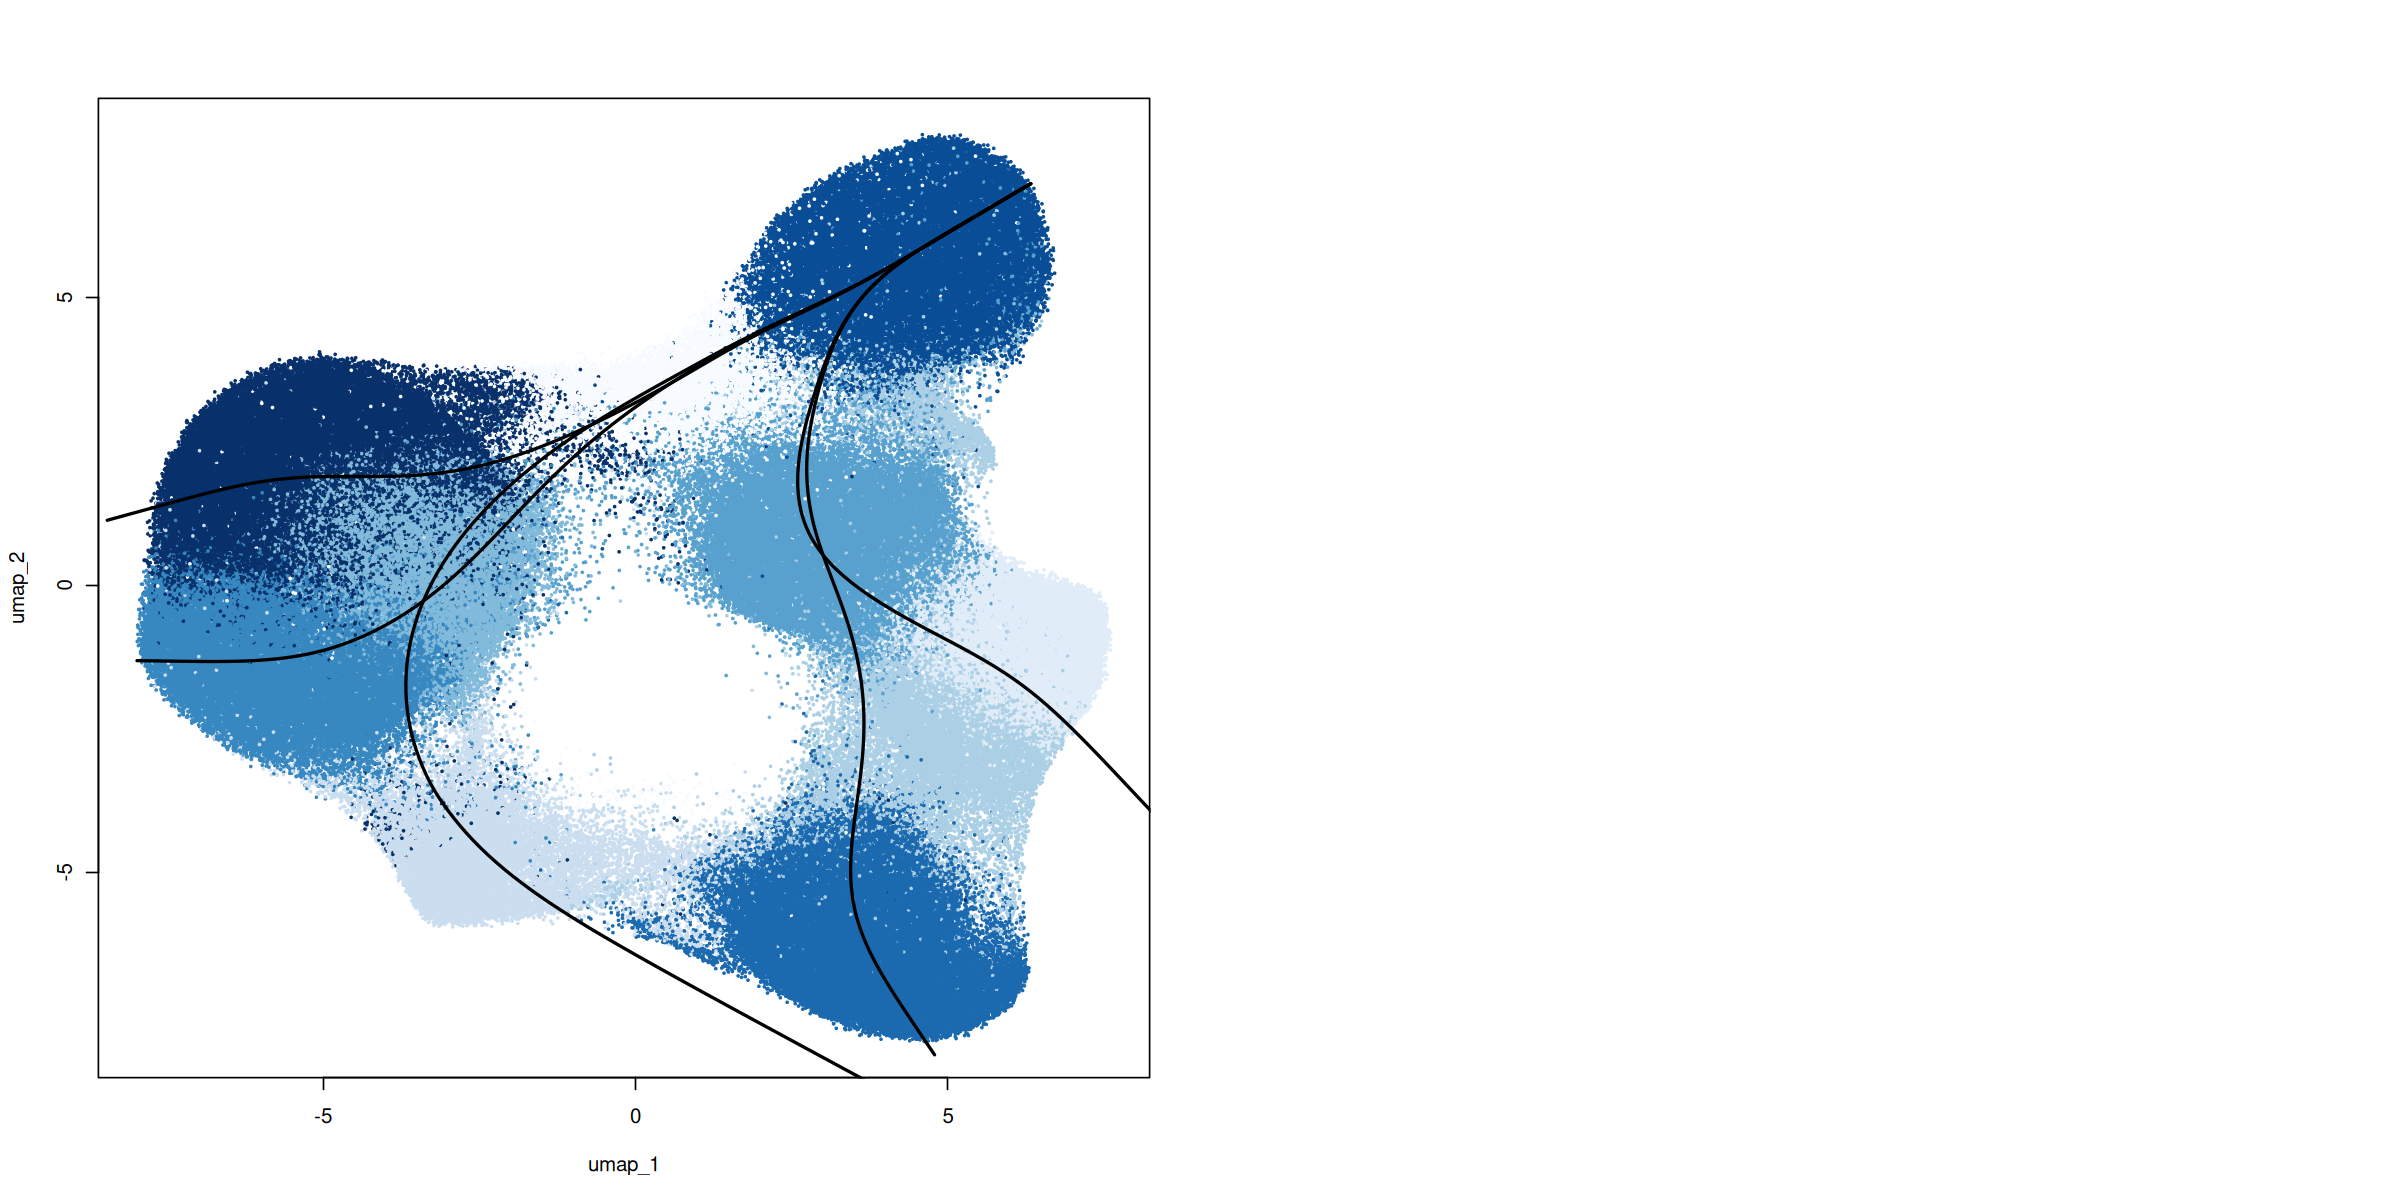

In [43]:
options(repr.plot.width = 20, repr.plot.height = 10)
par(mfrow = c(1, 2))
plot(dimred[, 1:2], col = pal[clustering], cex = 0.5, pch = 16)
for (i in levels(clustering)) {
    text(mean(dimred[clustering == i, 1]), mean(dimred[clustering == i, 2]), labels = i, font = 2)
}

colors2 <- rev(colorRampPalette(brewer.pal(11,'Blues'))(10))
plot(reducedDims(sce)$UMAP, col = colors2[as.factor(sce$seurat_clusters)], pch = 16, cex = 0.3)
lines(lineages2, lwd = 3, col = "black")


plot(reducedDims(sce)$UMAP, col = colors2[as.factor(sce$seurat_clusters)], pch = 16, cex = 0.3)
lines(SlingshotDataSet(sce), lwd=2, col='black')

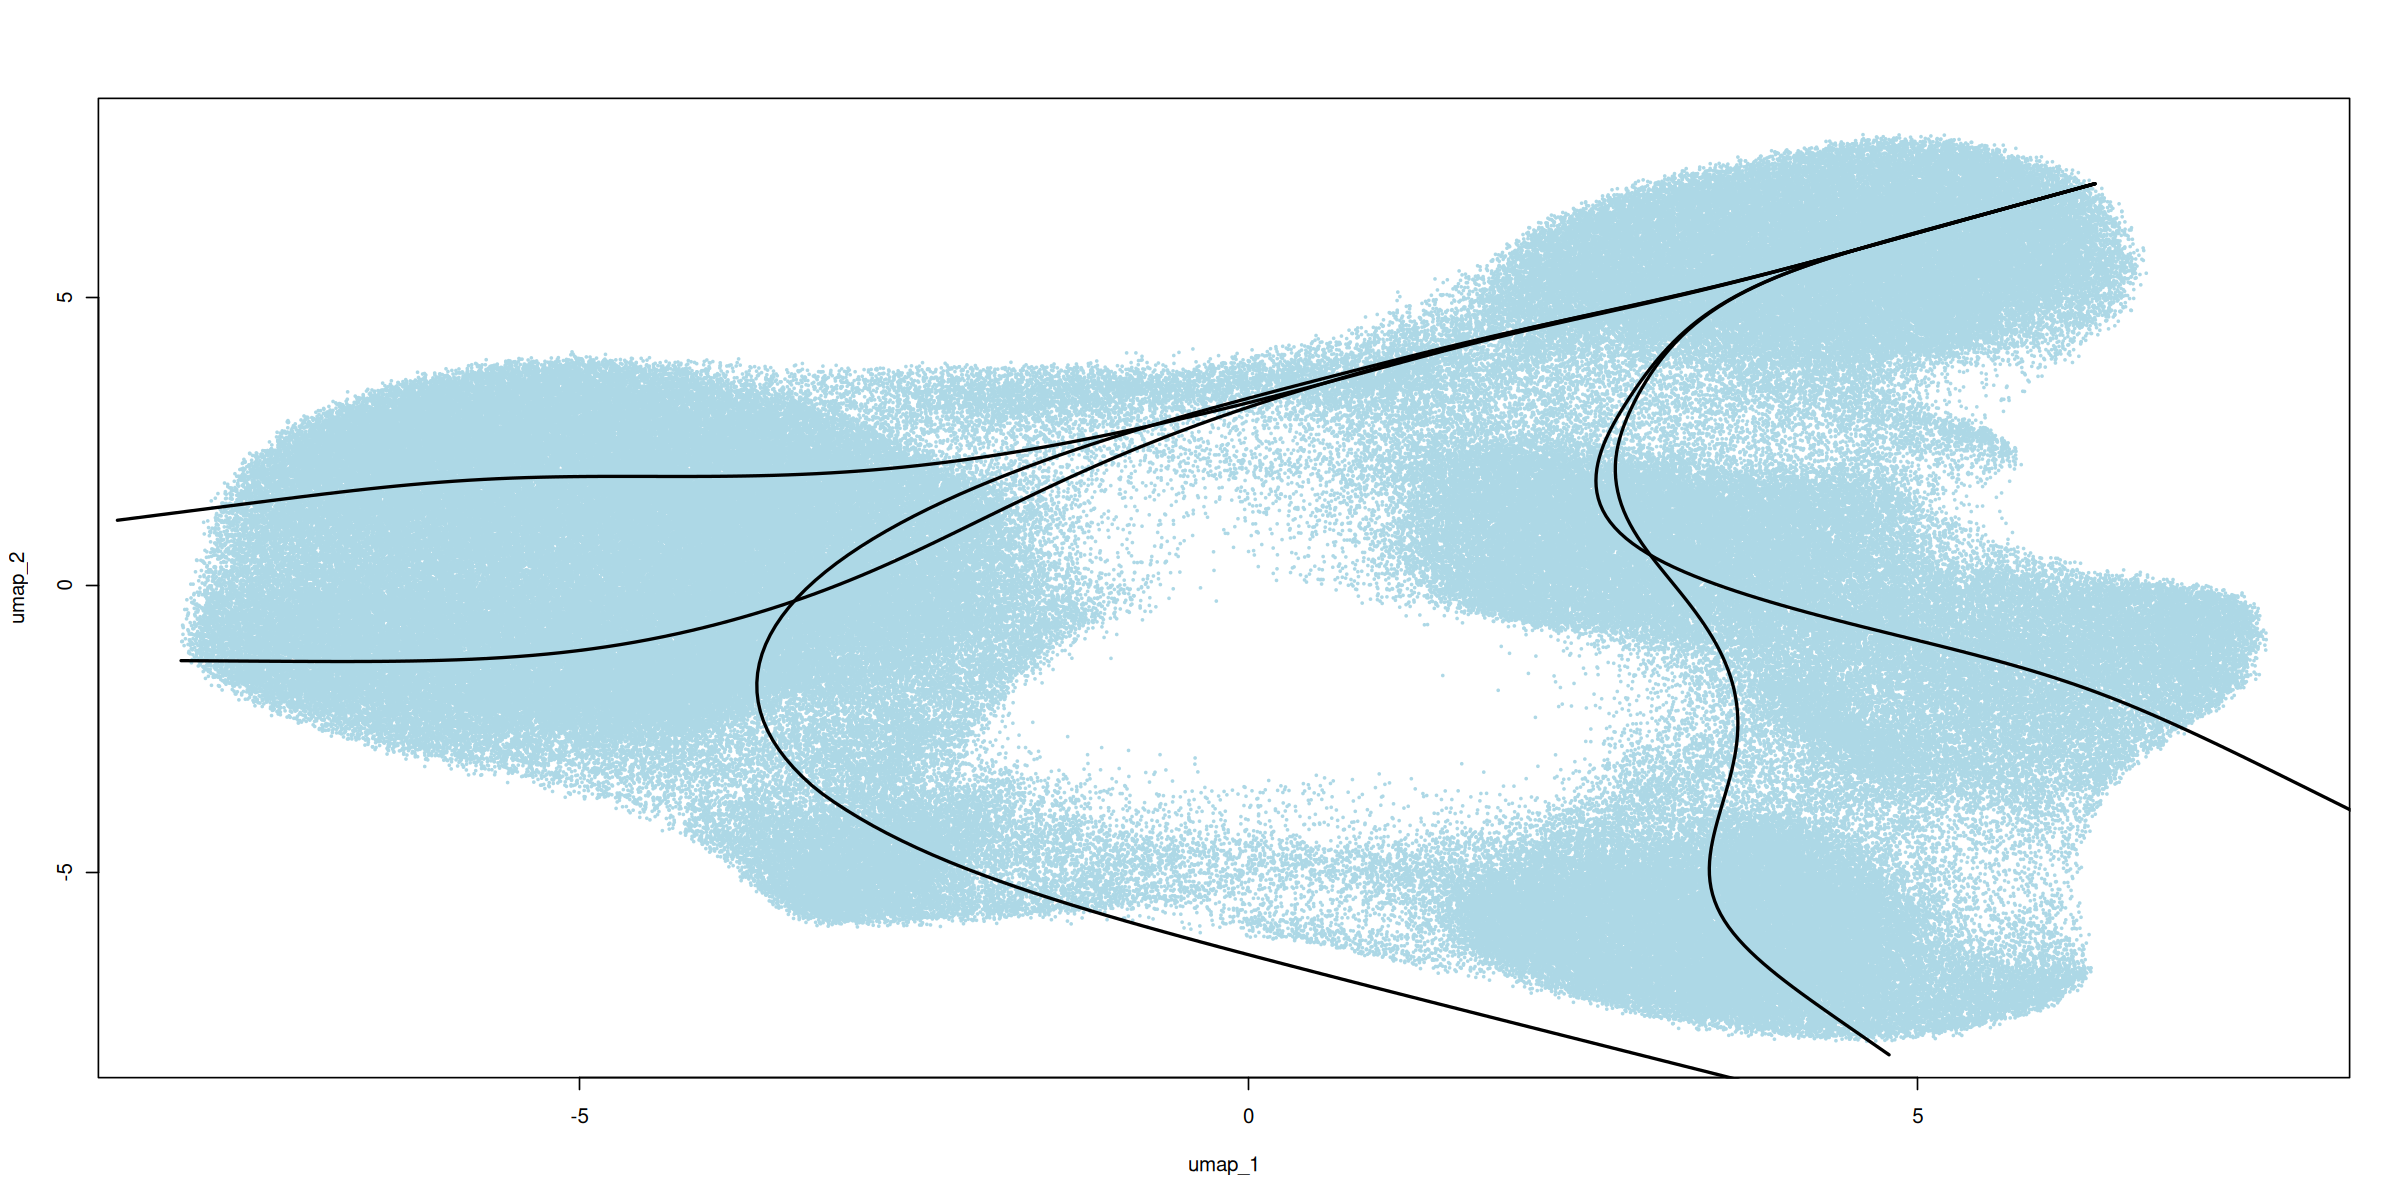

In [44]:
plot(reducedDims(sce)$UMAP, col = "lightblue", pch = 16, cex = 0.3)
lines(SlingshotDataSet(sce), lwd=2, col='black')

In [64]:
pallete4  <- unname(pallete2)[c(1,3,4,2,6,5,7,9,8,10,11)]

ERROR: Error in h(simpleError(msg, call)): error in evaluating the argument 'obj' in selecting a method for function 'unname': object 'pallete2' not found


In [ ]:
pallete4

In [ ]:
plot(legend = TRUE, reducedDims(sce)$UMAP, col = pallete4[as.factor(sce$seurat_clusters)], pch = 16, cex = 0.3)
lines(SlingshotDataSet(sce), lwd=2, col='black')

In [ ]:
plot(reducedDims(sce)$UMAP, col = pallete4[as.factor(sce$seurat_clusters)], pch = 16, cex = 0.3)
lines(SlingshotDataSet(sce), lwd=2, col='black')

In [197]:
pdf("figures/pseudotime/lineages.pdf", width = 5, height = 5)
plot(reducedDims(sce)$UMAP, col = colors2[as.factor(sce$seurat_clusters)], pch = 16, cex = 0.3)
lines(SlingshotDataSet(sce), lwd=2, col='black')
dev.off()

png 
  2

In [37]:
saveRDS(sce, "data/gut_5p_slingshot.rds")

In [7]:
gut_cdn$Sling_Lineage1  <- sce$slingPseudotime_1
gut_cdn$Sling_Lineage2  <- sce$slingPseudotime_2
gut_cdn$Sling_Lineage3  <- sce$slingPseudotime_3
gut_cdn$Sling_Lineage4  <- sce$slingPseudotime_4
gut_cdn$Sling_Lineage5  <- sce$slingPseudotime_5


## Pseudotime vs. clonal expansion

In [8]:
sce  <- readRDS("data/gut_5p_slingshot.rds")

In [9]:
gut_cdn$log_clone_abundance  %>% summary

ERROR: Error in (function (cond) : error in evaluating the argument 'object' in selecting a method for function 'summary': ‘log_clone_abundance’ not found in this Seurat object
 


In [ ]:
gut_cdn$clone_abundance  %>% summary

In [15]:
df_p  <- data.frame(sling1 = sce$slingPseudotime_1, 
                  sling2 = sce$slingPseudotime_2,
                 sling3 = sce$slingPseudotime_3,
                  sling4 = sce$slingPseudotime_4,
                  sling5 = sce$slingPseudotime_5,
                 clone_ab = gut_cdn$clone_abundance,
                 log_clone_ab = gut_cdn$log_clone_abundance,
                   sling1_ntile = ntile(sce$slingPseudotime_1, n = 10),
                   sling2_ntile = ntile(sce$slingPseudotime_2, n = 10),
                   sling3_ntile = ntile(sce$slingPseudotime_3, n = 10),
                   sling4_ntile = ntile(sce$slingPseudotime_4, n = 10),
                   sling5_ntile = ntile(sce$slingPseudotime_5, n = 10),
                   clone_ntile = ntile(gut_cdn$clone_abundance, n = 10),
                   clone_abundance_group = gut_cdn$clone_abundance_group,
                    clone_aa = gut_cdn$clone_aa
                   )

In [16]:
df_p$clone_ab  %>% table

.
     1      2      3      4      5      6      7      8      9     10     11 
188154  18228   5307   2212   1035    648    315    280    207     90     66 
    12     13     14     15     19     20     21     22     24     28     32 
    96     65     70     45     19     20     21     22     24     28     32 
    92 
    92 

In [17]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group)  %>% 
summarise(med_sling = median(sling1))

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


clone_aa,clone_abundance_group,med_sling
<chr>,<chr>,<dbl>
CDR3b CAAAPGGVDNEQFF CDR3a CAVGPIGFGNVLHC,1,0.9415170
CDR3b CAAARTSGANVLTF CDR3a CAVRKGNTGNQFYF,1,2.5321377
CDR3b CAACRGGEIRGTEAFF CDR3a CALSDPNTGNQFYF,1,1.3641347
CDR3b CAADHRDRDLYGYTF CDR3a CAPLASGGSYIPTF,1,11.6015479
CDR3b CAADLRTGGNIQYF CDR3a CAVRADRNTPLVF,1,8.8637243
CDR3b CAADRAAGNTIYF CDR3a CALGAIGGSARQLTF,1,10.5976975
CDR3b CAAEEARSGRPNSPLHF CDR3a CAYFQGAQKLVF,1,3.2270078
CDR3b CAAEGRGTDTQYF CDR3a CAFMKRVSGTYKYIF,1,0.6910667
CDR3b CAAFGDRGRFGGYTF CDR3a CAVSGGGADGLTF,1,7.6517935


In [56]:
df_p  <- df_p  %>% 
mutate(clone_abundance_group2 = case_when(clone_ab == 1 ~ "1",
                                          clone_ab >= 2 & clone_ab <= 10 ~ "2-9",
                                          clone_ab > 10 ~ ">10")) 

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


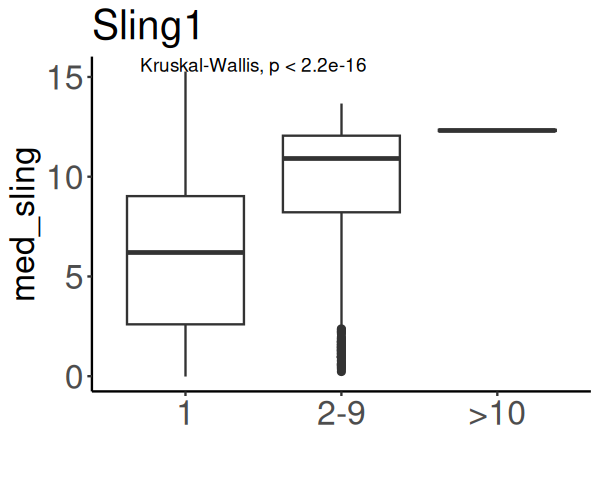

In [91]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ggplot(aes(x = factor(clone_abundance_group2, levels = c("1","2-9",">10")), y = med_sling)) +
xlab("") +
geom_boxplot() + 
theme_classic() +
ggtheme() +
ggpubr::stat_compare_means() +
ggtitle("Sling1")

ggsave("figures/pseudotime_and_TCR/sling1.svg", width = 9, height = 8, units = "cm", create.dir = T)

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


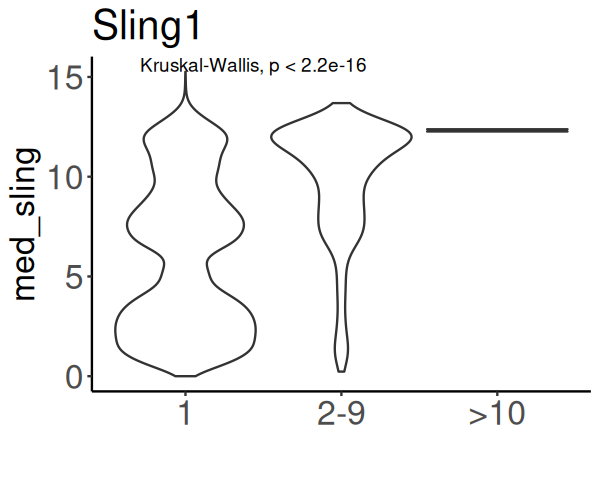

In [58]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ggplot(aes(x = factor(clone_abundance_group2, levels = c("1","2-9",">10")), y = med_sling)) +
xlab("") +
geom_violin(scale = "width") + 
#geom_jitter() +
theme_classic() +
ggtheme() +
ggpubr::stat_compare_means() +
ggtitle("Sling1")

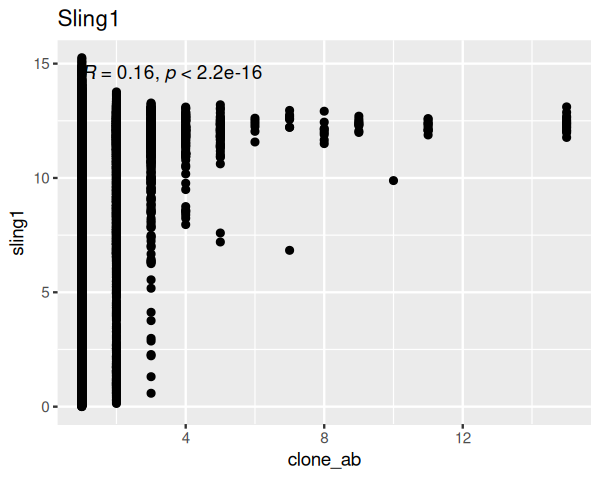

In [61]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ggplot(aes(x = clone_ab, y = med_sling))  +
geom_point() +
ggpubr::stat_cor() +
ggtitle("Sling1")

In [66]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ungroup  %>% 
mutate(ntile_sling = ntile(med_sling, n = 10))

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


clone_aa,clone_abundance_group2,clone_ab,med_sling,ntile_sling
<chr>,<chr>,<dbl>,<dbl>,<int>
CDR3b CAAAPGGVDNEQFF CDR3a CAVGPIGFGNVLHC,1,1,0.9415170,1
CDR3b CAAARTSGANVLTF CDR3a CAVRKGNTGNQFYF,1,1,2.5321377,1
CDR3b CAACRGGEIRGTEAFF CDR3a CALSDPNTGNQFYF,1,1,1.3641347,1
CDR3b CAADHRDRDLYGYTF CDR3a CAPLASGGSYIPTF,1,1,11.6015479,1
CDR3b CAADLRTGGNIQYF CDR3a CAVRADRNTPLVF,1,1,8.8637243,1
CDR3b CAADRAAGNTIYF CDR3a CALGAIGGSARQLTF,1,1,10.5976975,1
CDR3b CAAEEARSGRPNSPLHF CDR3a CAYFQGAQKLVF,1,1,3.2270078,1
CDR3b CAAEGRGTDTQYF CDR3a CAFMKRVSGTYKYIF,1,1,0.6910667,1
CDR3b CAAFGDRGRFGGYTF CDR3a CAVSGGGADGLTF,1,1,7.6517935,1


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


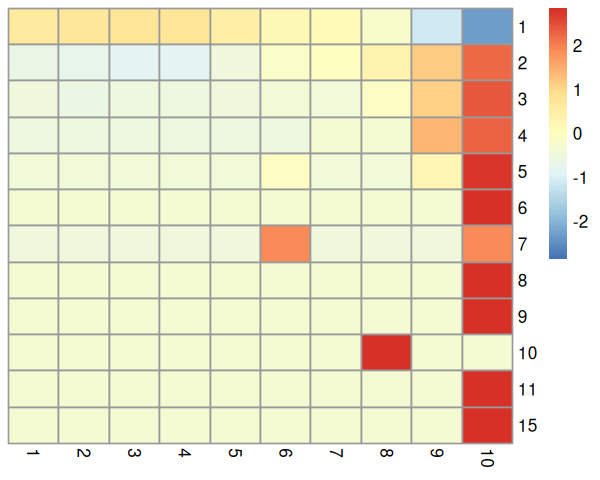

In [79]:
df_sling  <- df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ungroup  %>% 
mutate(ntile_sling = ntile(med_sling, n = 10))

mtx_sling  <- df_sling  %>% dplyr::select(clone_ab, ntile_sling)  %>% 
group_by(clone_ab, ntile_sling)  %>% 
tally()  %>% 
pivot_wider(names_from = ntile_sling, values_from = n, values_fill = 0)  %>% 
column_to_rownames("clone_ab")  %>% 
as.matrix() 

pheatmap::pheatmap(mtx_sling, scale = "row", cluster_rows = F, cluster_cols = F)

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


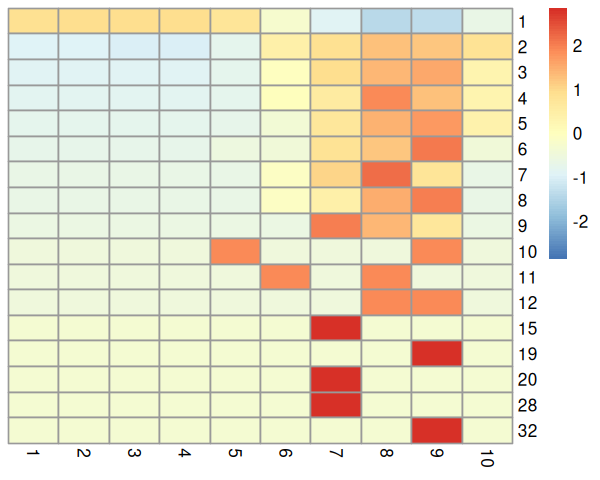

In [81]:
df_sling  <- df_p  %>% dplyr::filter(!is.na(sling2) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling2))  %>% 
ungroup  %>% 
mutate(ntile_sling = ntile(med_sling, n = 10))

mtx_sling  <- df_sling  %>% dplyr::select(clone_ab, ntile_sling)  %>% 
group_by(clone_ab, ntile_sling)  %>% 
tally()  %>% 
pivot_wider(names_from = ntile_sling, values_from = n, values_fill = 0)  %>% 
column_to_rownames("clone_ab")  %>% 
as.matrix() 

pheatmap::pheatmap(mtx_sling, scale = "row", cluster_rows = F, cluster_cols = F)

In [48]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA")) 

,sling1,sling2,sling3,sling4,sling5,clone_ab,log_clone_ab,sling1_ntile,sling2_ntile,sling3_ntile,sling4_ntile,sling5_ntile,clone_ntile,clone_abundance_group,clone_aa,clone_abundance_group2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
AAACCTGCATCGGACC-1_1193610_1_1_1,10.4459095,NA,NA,NA,NA,2,1,9,NA,NA,NA,NA,9,2,CDR3b CASSLQGLSSSYEQYF CDR3a CATDLDGANSKLTF,2-9
AAACCTGTCGCCAGCA-1_1193610_1_1_1,7.7435835,NA,7.681388,NA,NA,1,0,7,NA,5,NA,NA,1,1,CDR3b CATSPTSGQGALYNEQFF CDR3a CALVGSSNTGKLIF,1
AAACCTGTCGCGATCG-1_1193610_1_1_1,2.6180765,2.5667506,2.612299,2.5677228,2.5691318,1,0,3,3,2,3,3,1,1,CDR3b CASSLWGVSGNTIYF CDR3a CAENRETSYDKVIF,1
AAACCTGTCTTCGGTC-1_1193610_1_1_1,0.8083148,0.8121457,0.807851,0.8117275,0.8119254,1,0,1,1,1,1,1,1,1,CDR3b CASSTGQENQPQHF CDR3a CALIPMDSSYKLIF,1
AAACGGGCAGGTGCCT-1_1193610_1_1_1,8.1620010,NA,8.360145,NA,NA,1,0,7,NA,6,NA,NA,1,1,CDR3b CASSEGTGFANEKLFF CDR3a CASPTGGGTALIF,1
AAAGCAAGTTGGTAAA-1_1193610_1_1_1,1.2988273,1.3076915,1.298775,1.3074787,1.3074604,1,0,1,1,1,1,1,1,1,CDR3b CASSQGLNTGELFF CDR3a CALSDSSPNTGNQFYF,1
AAAGCAATCGTTACGA-1_1193610_1_1_1,1.6804375,1.6786962,1.677961,1.6783399,1.6787465,1,0,2,2,2,2,2,1,1,CDR3b CASSPLRGKGYGYTF CDR3a CAYNNNDMRF,1
AAAGTAGCACTGTCGG-1_1193610_1_1_1,2.4780444,2.5983976,2.474051,2.5954065,2.5910633,1,0,3,3,2,3,3,1,1,CDR3b CASSYHTGEDYGYTF CDR3a CAAIERNTGNQFYF,1
AAATGCCAGCCGCCTA-1_1193610_1_1_1,3.8244599,3.9660736,3.814006,3.9665028,3.9675164,1,0,4,4,4,4,4,1,1,CDR3b CASSQVGGPDLDVVGYTF CDR3a CALSFSGTYKYIF,1


In [53]:
df_lm  <- df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))   %>% 
dplyr::select(sling1, clone_ab)

fit <- lm(as.numeric(clone_ab) ~ log(sling1), data = df_lm)
summary(fit)


Call:
lm(formula = as.numeric(clone_ab) ~ log(sling1), data = df_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-0.1207 -0.0905 -0.0648 -0.0165 13.8938 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 0.968316   0.003310  292.50   <2e-16 ***
log(sling1) 0.055906   0.001875   29.82   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.399 on 61878 degrees of freedom
Multiple R-squared:  0.01417,	Adjusted R-squared:  0.01415 
F-statistic: 889.2 on 1 and 61878 DF,  p-value: < 2.2e-16


In [54]:
df_lm

,sling1,clone_ab
,<dbl>,<dbl>
AAACCTGCATCGGACC-1_1193610_1_1_1,10.4459095,2
AAACCTGTCGCCAGCA-1_1193610_1_1_1,7.7435835,1
AAACCTGTCGCGATCG-1_1193610_1_1_1,2.6180765,1
AAACCTGTCTTCGGTC-1_1193610_1_1_1,0.8083148,1
AAACGGGCAGGTGCCT-1_1193610_1_1_1,8.1620010,1
AAAGCAAGTTGGTAAA-1_1193610_1_1_1,1.2988273,1
AAAGCAATCGTTACGA-1_1193610_1_1_1,1.6804375,1
AAAGTAGCACTGTCGG-1_1193610_1_1_1,2.4780444,1
AAATGCCAGCCGCCTA-1_1193610_1_1_1,3.8244599,1


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


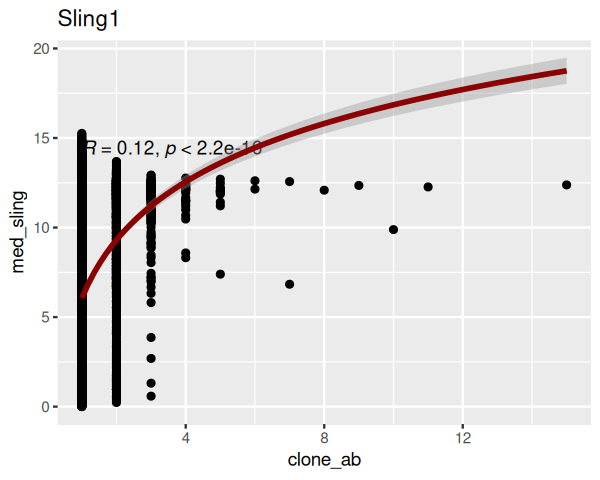

In [51]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ggplot(aes(x = clone_ab, y = med_sling))  +
geom_point() +
ggpubr::stat_cor() +
ggtitle("Sling1") +
stat_smooth(method = "lm", formula = y ~ log(x), se = TRUE, color = "darkred", size = 1.2) 

In [55]:
# Ensure pseudotime is nonnegative and finite
df_lm <- subset(df_lm, is.finite(sling1) & is.finite(clone_ab))

# If any sling1 < 0 (can happen), shift to start at 0
if (min(df_lm$sling1) < 0) {
  df_lm$sling1 <- df_lm$sling1 - min(df_lm$sling1)
}

In [56]:
m_lm <- lm(as.numeric(clone_ab) ~ log1p(sling1), data = df_lm)
summary(m_lm)


Call:
lm(formula = as.numeric(clone_ab) ~ log1p(sling1), data = df_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-0.1364 -0.0953 -0.0621 -0.0064 13.8836 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)   0.906248   0.004819  188.08   <2e-16 ***
log1p(sling1) 0.082521   0.002527   32.66   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3984 on 61878 degrees of freedom
Multiple R-squared:  0.01695,	Adjusted R-squared:  0.01693 
F-statistic:  1067 on 1 and 61878 DF,  p-value: < 2.2e-16


In [52]:
fit_nls <- nls(as.numeric(clone_ab) ~ a + b * log(1 + c * sling1),
               data = df_lm,
               start = list(a = 1, b = 1, c = 1))
summary(fit_nls)

# Add curve to plot
df_p$pred <- predict(fit_nls)

df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ggplot(aes(x = clone_ab, y = med_sling))  +
geom_point() +
ggpubr::stat_cor() +
ggtitle("Sling1") +
  geom_line(aes(y = pred), color = "blue", lwd = 1.2)

Warning message in log(1 + c * sling1):
“NaNs produced”


ERROR: Error in numericDeriv(form[[3L]], names(ind), env, central = nDcentral): Missing value or an infinity produced when evaluating the model


`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


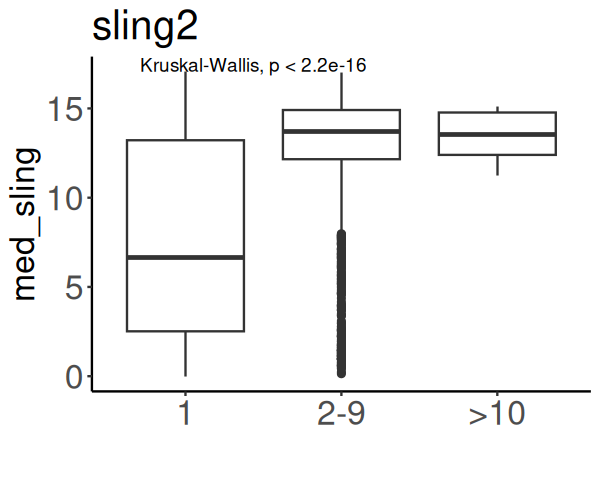

In [90]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_p  %>% dplyr::filter(!is.na(sling2) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2)  %>% 
summarise(med_sling = mean(sling2))  %>% 
ggplot(aes(x = factor(clone_abundance_group2, levels = c("1","2-9",">10")), y = med_sling)) +
xlab("") +
geom_boxplot() + 
theme_classic() +
ggtheme() +
ggpubr::stat_compare_means() +
ggtitle("sling2")

ggsave("figures/pseudotime_and_TCR/sling2.svg", width = 9, height = 8, units = "cm", create.dir = T)

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


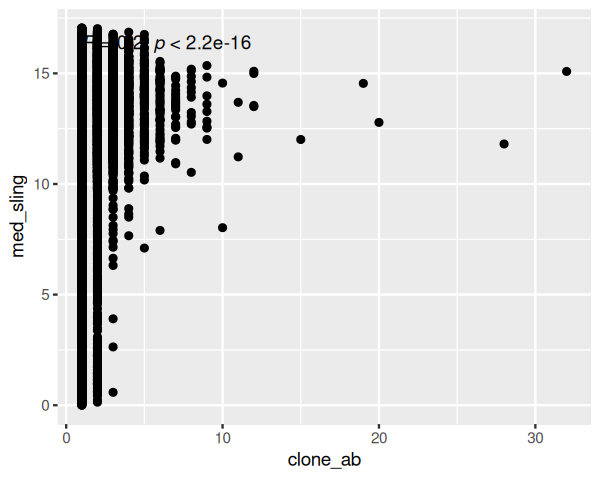

In [32]:
df_p  %>% dplyr::filter(!is.na(sling2) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling2))  %>% 
ggplot(aes(x = clone_ab, y = med_sling))  +
geom_point() +
ggpubr::stat_cor() +
ggtitle("Sling2")

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


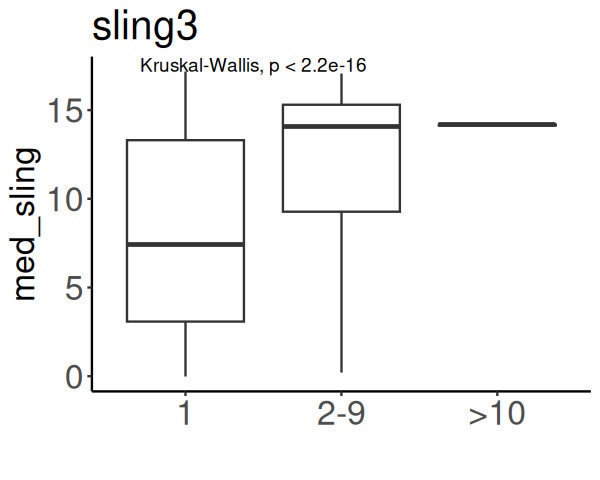

In [89]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_p  %>% dplyr::filter(!is.na(sling3) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2)  %>% 
summarise(med_sling = mean(sling3))  %>% 
ggplot(aes(x = factor(clone_abundance_group2, levels = c("1","2-9",">10")), y = med_sling)) +
xlab("") +
geom_boxplot() + 
theme_classic() +
ggtheme() +
ggpubr::stat_compare_means() +
ggtitle("sling3")

ggsave("figures/pseudotime_and_TCR/sling3.svg", width = 9, height = 8, units = "cm", create.dir = T)

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


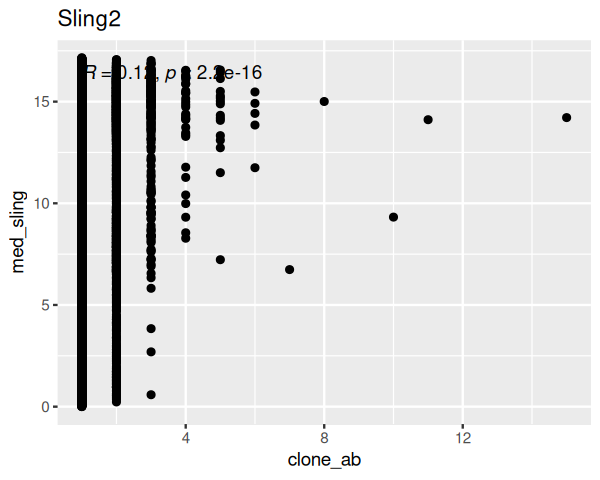

In [35]:
df_p  %>% dplyr::filter(!is.na(sling3) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling3))  %>% 
ggplot(aes(x = clone_ab, y = med_sling))  +
geom_point() +
ggpubr::stat_cor() +
ggtitle("Sling2")

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


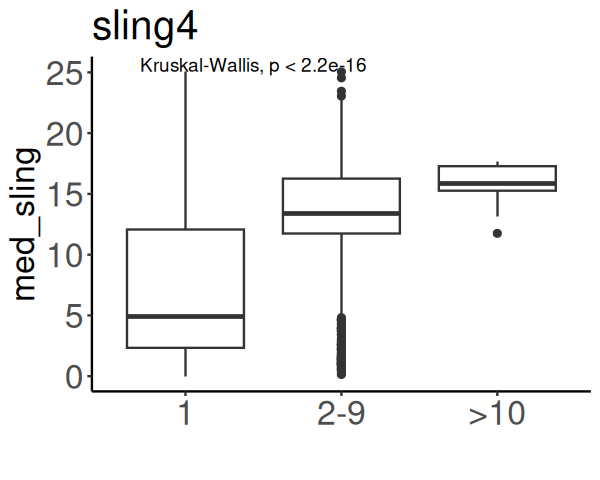

In [88]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_p  %>% dplyr::filter(!is.na(sling4) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2)  %>% 
summarise(med_sling = mean(sling4))  %>% 
ggplot(aes(x = factor(clone_abundance_group2, levels = c("1","2-9",">10")), y = med_sling)) +
xlab("") +
geom_boxplot() + 
theme_classic() +
ggtheme() +
ggpubr::stat_compare_means() +
ggtitle("sling4")

ggsave("figures/pseudotime_and_TCR/sling4.svg", width = 9, height = 8, units = "cm", create.dir = T)

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


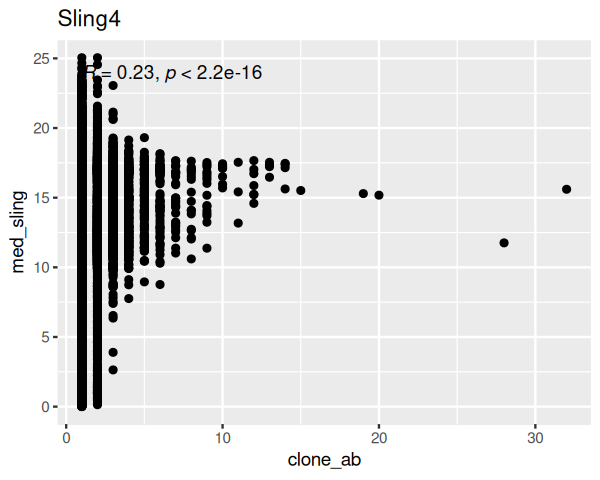

In [36]:
df_p  %>% dplyr::filter(!is.na(sling4) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling4))  %>% 
ggplot(aes(x = clone_ab, y = med_sling))  +
geom_point() +
ggpubr::stat_cor() +
ggtitle("Sling4")

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


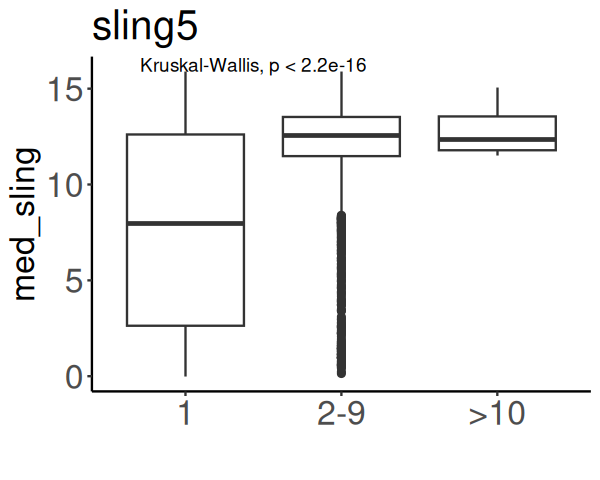

In [87]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_p  %>% dplyr::filter(!is.na(sling5) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2)  %>% 
summarise(med_sling = mean(sling5))  %>% 
ggplot(aes(x = factor(clone_abundance_group2, levels = c("1","2-9",">10")), y = med_sling)) +
xlab("") +
geom_boxplot() + 
theme_classic() +
ggtheme() +
ggpubr::stat_compare_means() +
ggtitle("sling5")

ggsave("figures/pseudotime_and_TCR/sling5.svg", width = 9, height = 8, units = "cm", create.dir = T)

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


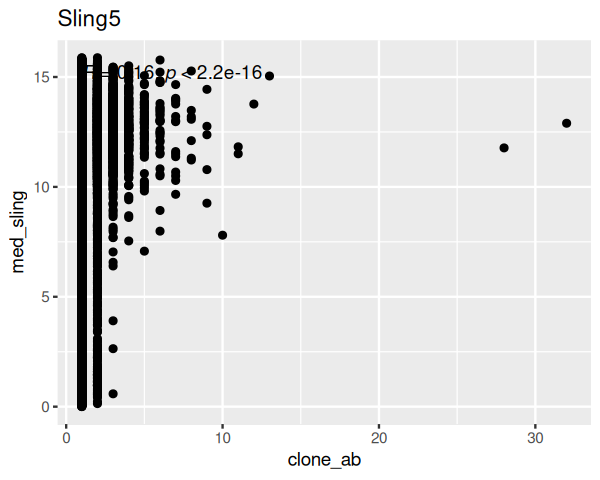

In [37]:
df_p  %>% dplyr::filter(!is.na(sling5) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling5))  %>% 
ggplot(aes(x = clone_ab, y = med_sling))  +
geom_point() +
ggpubr::stat_cor() +
ggtitle("Sling5")

In [42]:
df_p  %>% dplyr::filter(!is.na(sling5) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = median(sling5))    %>% 
ungroup  %>% 
group_by(clone_ab)  %>% 
summarise(med_sling2 = median(med_sling))    

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


clone_ab,med_sling2
<dbl>,<dbl>
1,7.948280
2,12.516694
3,12.770629
4,12.565008
5,12.949940
6,12.833252
7,13.050404
8,12.761498
9,12.172782


In [45]:
df_p  %>% dplyr::filter(!is.na(sling4) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab)  %>% 
summarise(med_sling = mean(sling4))    %>% 
ungroup  %>% 
group_by(clone_ab)  %>% 
summarise(med_sling2 = mean(med_sling))    

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2'. You
can override using the `.groups` argument.


clone_ab,med_sling2
<dbl>,<dbl>
1,7.337535
2,13.309806
3,14.089513
4,14.214827
5,14.674215
6,15.038927
7,14.870701
8,14.872875
9,15.295288


## Mean pseudotime in groups

In [93]:
df_p$condition  <- gut_cdn$diagnosis
df_p$tissue  <- gut_cdn$tissue
df_p$layer  <- gut_cdn$layer
df_p$timepoint  <- gut_cdn$timepoint

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab'. You can override using the `.groups` argument.


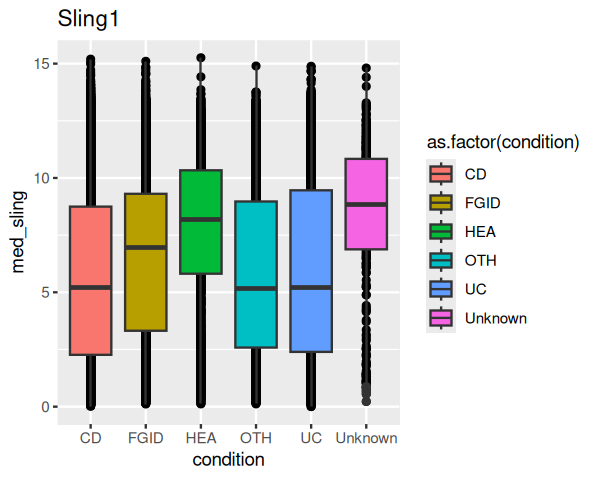

In [60]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, condition)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ggplot(aes(x = condition, y = med_sling))  +
geom_point() +
geom_boxplot(aes(fill = as.factor(condition))) +
ggpubr::stat_cor() +
ggtitle("Sling1")

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab'. You can override using the `.groups` argument.


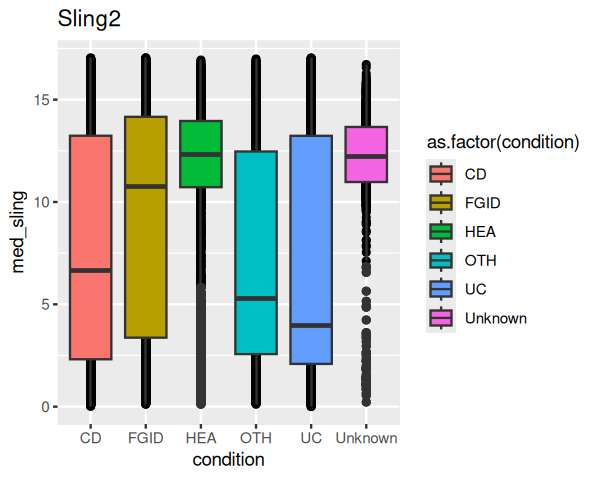

In [58]:
df_p  %>% dplyr::filter(!is.na(sling2) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, condition)  %>% 
summarise(med_sling = mean(sling2))  %>% 
ggplot(aes(x = condition, y = med_sling))  +
geom_point() +
geom_boxplot(aes(fill = as.factor(condition))) +
ggpubr::stat_cor() +
ggtitle("Sling2")

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab'. You can override using the `.groups` argument.


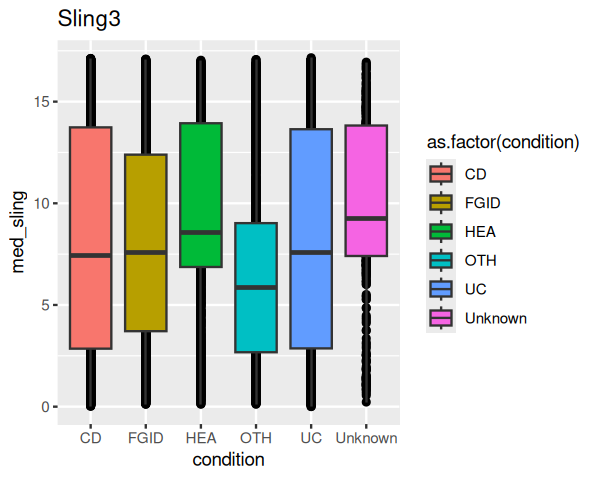

In [57]:
df_p  %>% dplyr::filter(!is.na(sling3) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, condition)  %>% 
summarise(med_sling = mean(sling3))  %>% 
ggplot(aes(x = condition, y = med_sling))  +
geom_point() +
geom_boxplot(aes(fill = as.factor(condition))) +
ggpubr::stat_cor() +
ggtitle("Sling3")

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab'. You can override using the `.groups` argument.


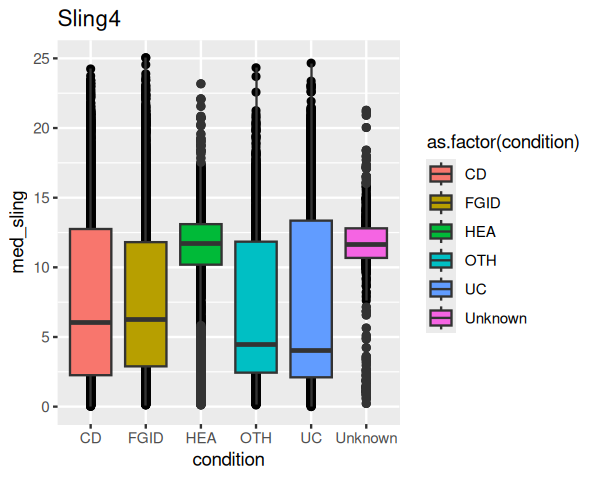

In [56]:
df_p  %>% dplyr::filter(!is.na(sling4) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, condition)  %>% 
summarise(med_sling = mean(sling4))  %>% 
ggplot(aes(x = condition, y = med_sling))  +
geom_point() +
geom_boxplot(aes(fill = as.factor(condition))) +
ggpubr::stat_cor() +
ggtitle("Sling4")

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab'. You can override using the `.groups` argument.


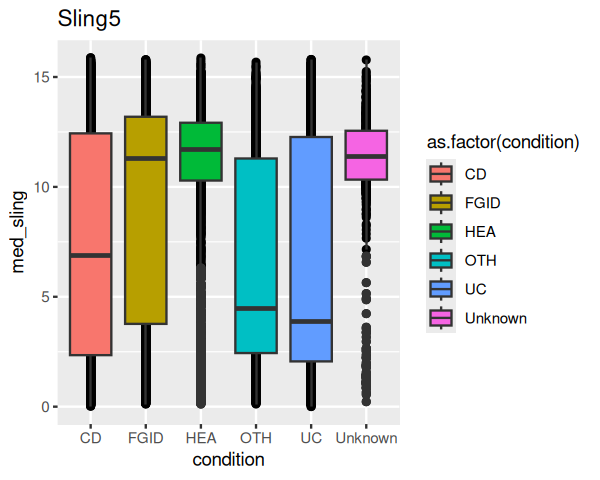

In [55]:
df_p  %>% dplyr::filter(!is.na(sling5) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, condition)  %>% 
summarise(med_sling = mean(sling5))  %>% 
ggplot(aes(x = condition, y = med_sling))  +
geom_point() +
geom_boxplot(aes(fill = as.factor(condition))) +
ggpubr::stat_cor() +
ggtitle("Sling5")

## Clones in time

In [54]:
df_p$patient  <- gut_cdn$participant_id
df_p$diagnosis  <- gut_cdn$diagnosis
df_p$response  <- gut_cdn$antitnf_response

In [58]:
df_p$timepoint  <- gut_cdn$timepoint

### T0 vs R

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint'. You can override using the `.groups` argument.


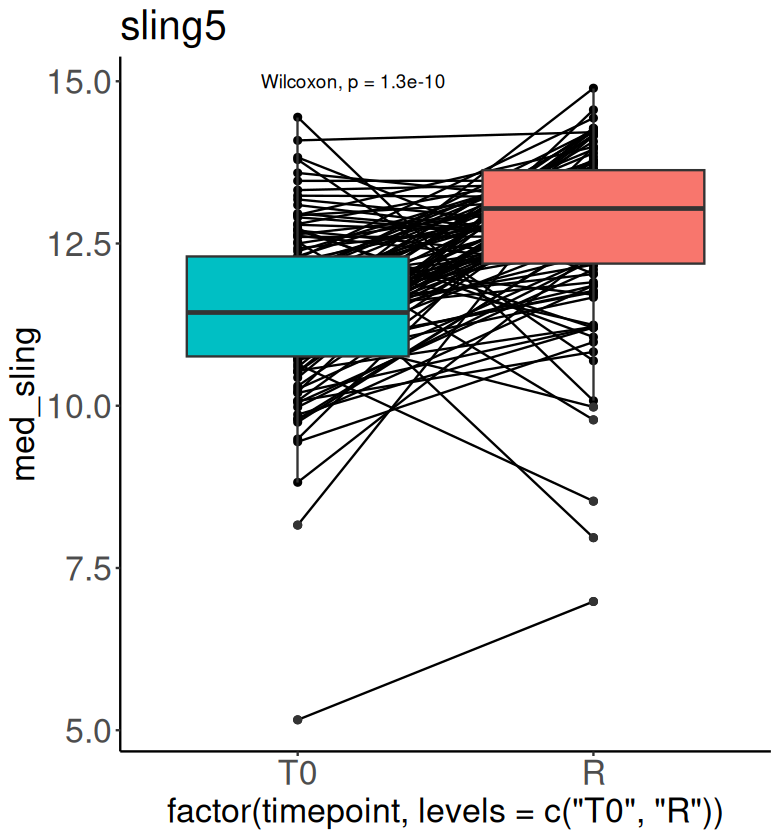

In [62]:
options(repr.plot.width = 6.5, repr.plot.height = 7)
df_p  %>% dplyr::filter(!is.na(sling5) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient)  %>% 
summarise(med_sling = mean(sling5))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling5") +
theme_classic() +
ggtheme() +
NoLegend()

ggsave("figures/pseudotime_and_TCR/sling5_T0_R.svg", width = 6.5, height = 7, units = "cm", create.dir = T)

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint'. You can override using the `.groups` argument.


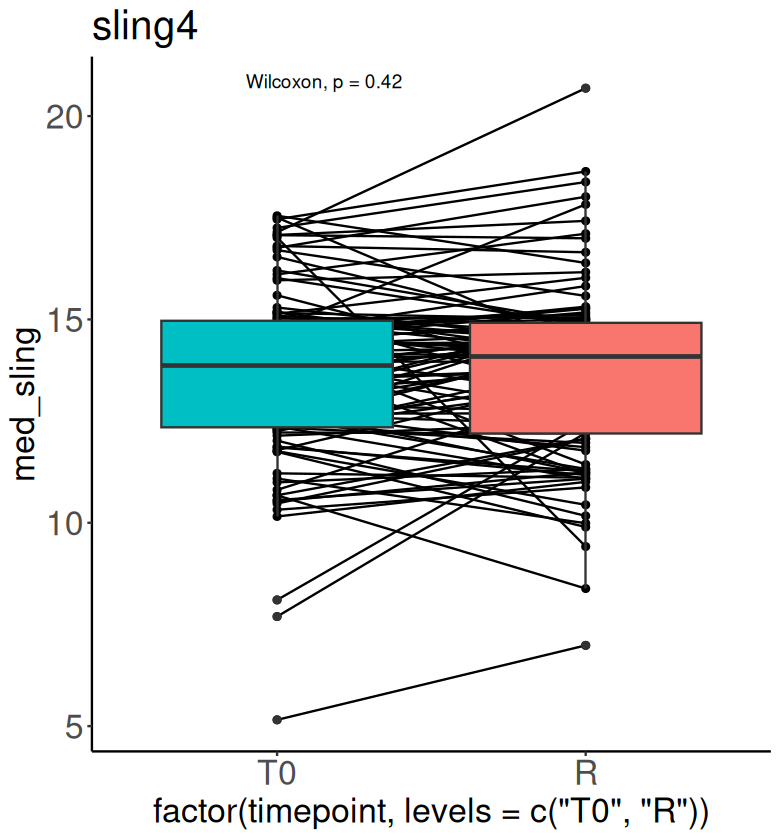

In [63]:
df_p  %>% dplyr::filter(!is.na(sling4) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient)  %>% 
summarise(med_sling = mean(sling4))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling4") +
theme_classic() +
ggtheme() +
NoLegend()

ggsave("figures/pseudotime_and_TCR/sling4_T0_R.svg", width = 6.5, height = 7, units = "cm", create.dir = T)

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint'. You can override using the `.groups` argument.


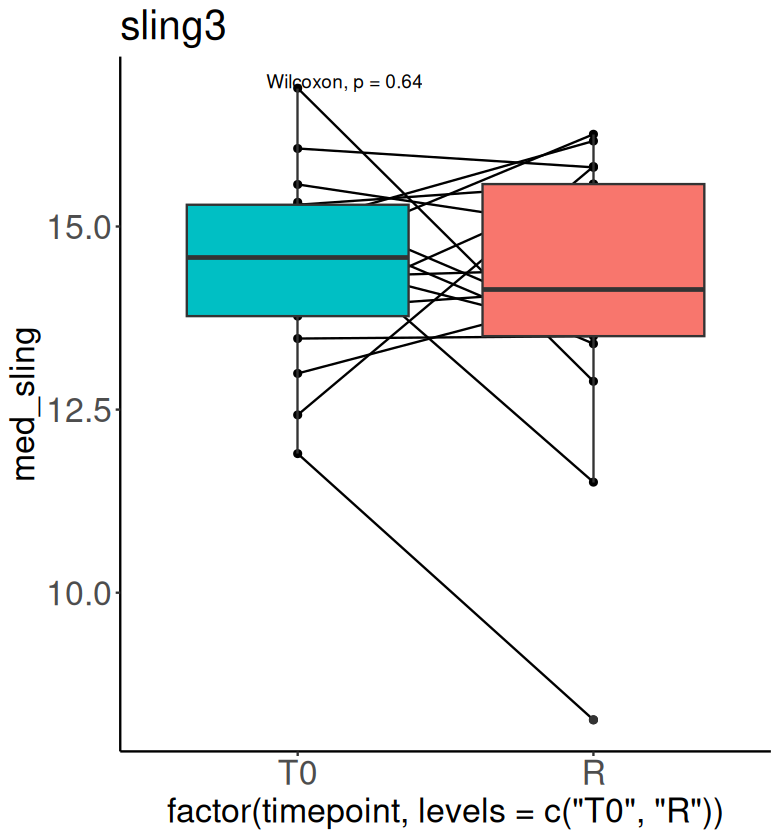

In [64]:
df_p  %>% dplyr::filter(!is.na(sling3) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient)  %>% 
summarise(med_sling = mean(sling3))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling3") +
theme_classic() +
ggtheme() +
NoLegend()

ggsave("figures/pseudotime_and_TCR/sling3_T0_R.svg",  width = 6.5, height = 7, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint'. You can override using the `.groups` argument.


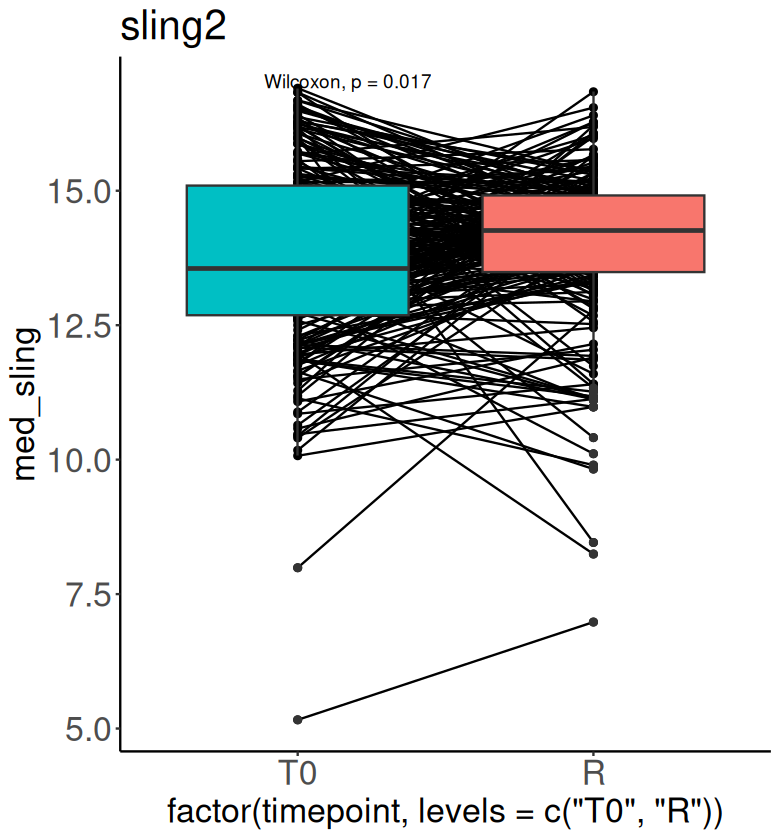

In [65]:
df_p  %>% dplyr::filter(!is.na(sling2) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient)  %>% 
summarise(med_sling = mean(sling2))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling2") +
theme_classic() +
ggtheme() +
NoLegend()

ggsave("figures/pseudotime_and_TCR/sling2_T0_R.svg",  width = 6.5, height = 7, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint'. You can override using the `.groups` argument.


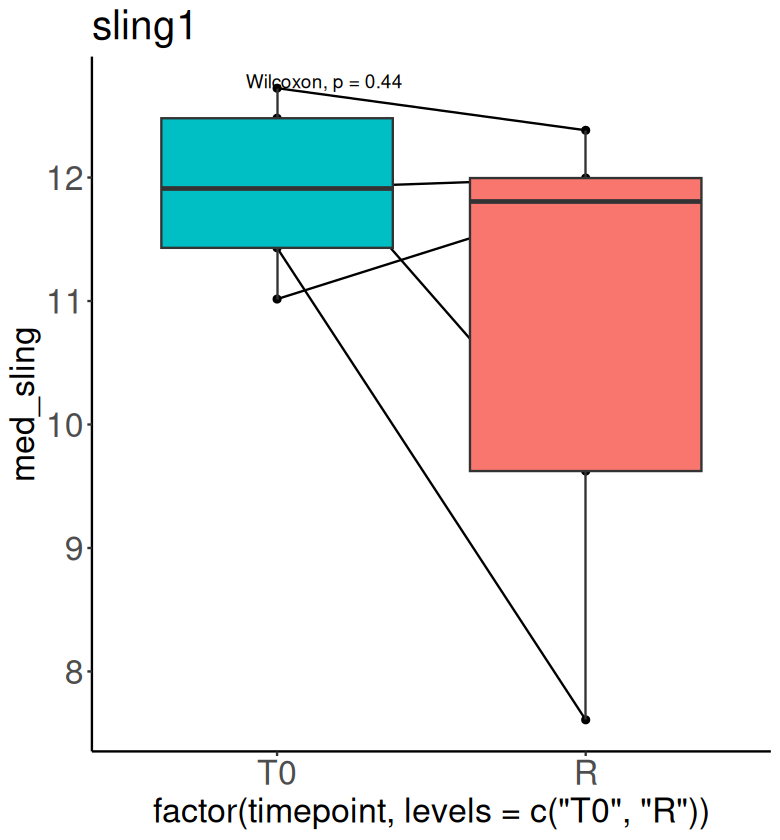

In [66]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling1") +
theme_classic() +
ggtheme() +
NoLegend()

ggsave("figures/pseudotime_and_TCR/sling1_T0_R.svg",  width = 6.5, height = 7, units = "cm", create.dir = T)


### Divided by response in CD

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


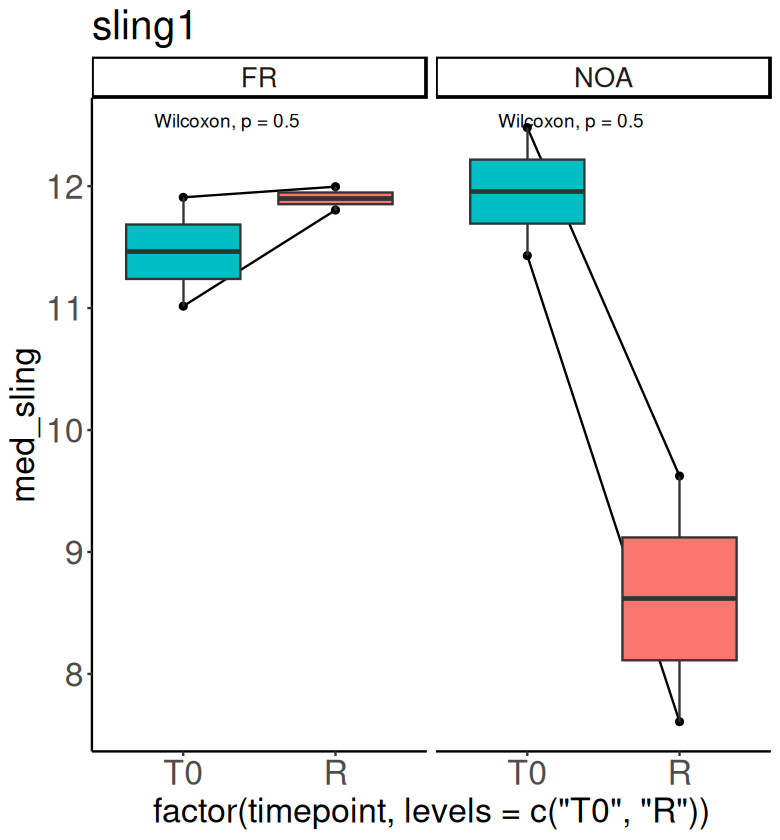

In [67]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa, diagnosis, response, sep = "___"))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient, -diagnosis, -response)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
separate(clone_aa, into = c("patient", "clone_aa", "diagnosis", "response"), sep = "___")  %>% 
dplyr::filter(diagnosis == "CD")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
facet_wrap(~response) +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling1") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling1_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


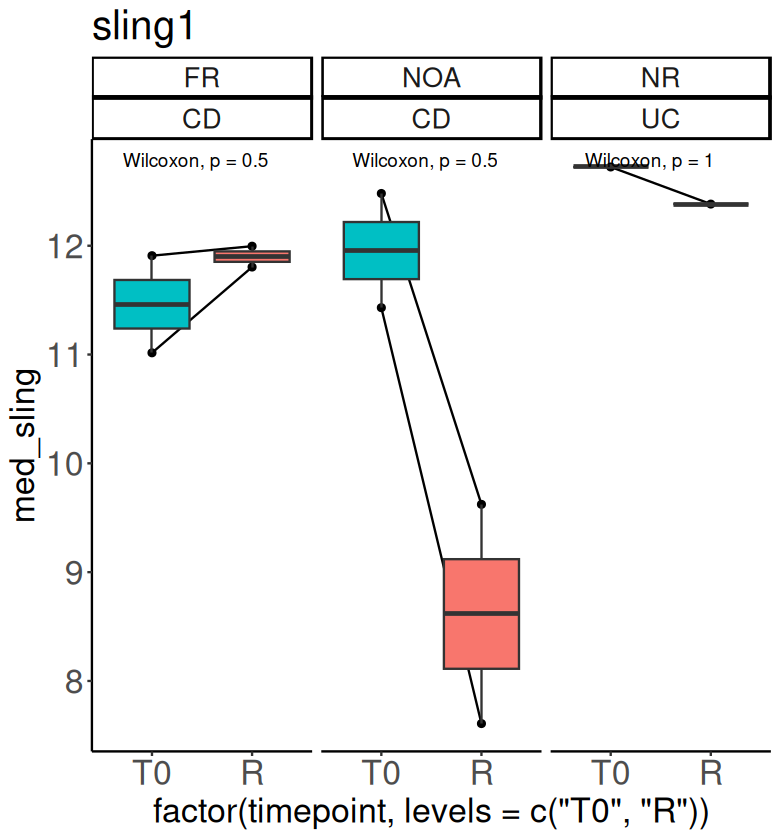

In [68]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa, diagnosis, response, sep = "___"))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient, -diagnosis, -response)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
separate(clone_aa, into = c("patient", "clone_aa", "diagnosis", "response"), sep = "___")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
facet_wrap(~response+diagnosis) +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling1") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling1_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


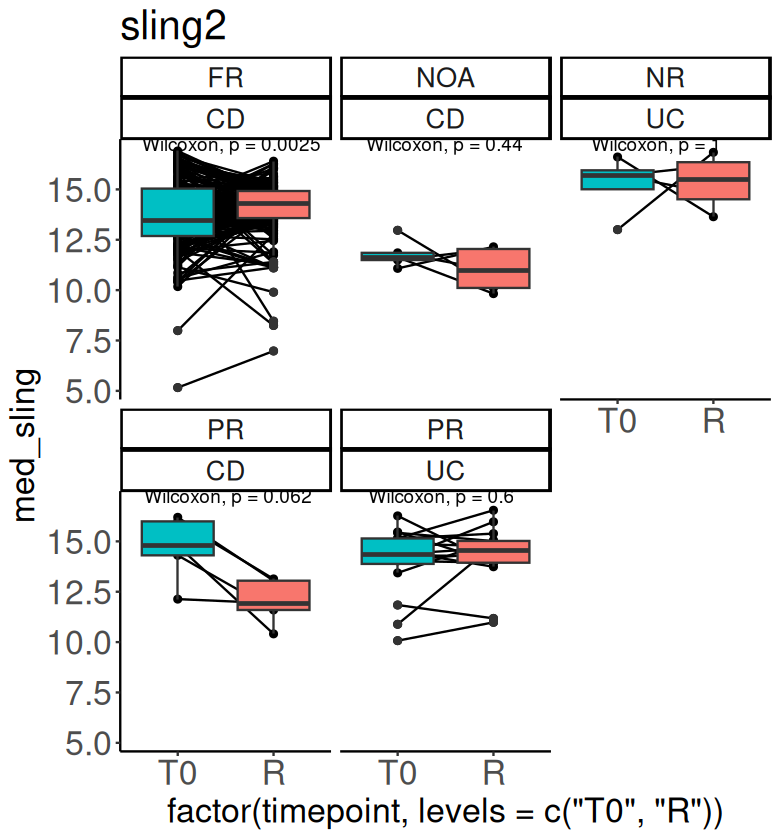

In [69]:
df_p  %>% dplyr::filter(!is.na(sling2) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling2))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa, diagnosis, response, sep = "___"))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient, -diagnosis, -response)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
separate(clone_aa, into = c("patient", "clone_aa", "diagnosis", "response"), sep = "___")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
facet_wrap(~response+diagnosis) +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling2") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling2_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


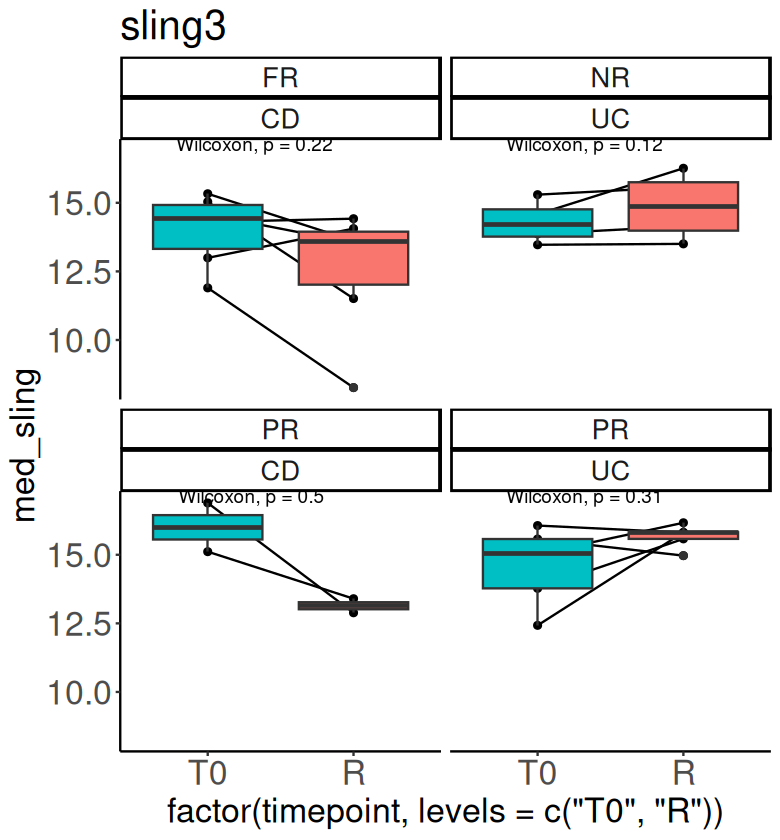

In [70]:
df_p  %>% dplyr::filter(!is.na(sling3) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling3))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa, diagnosis, response, sep = "___"))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient, -diagnosis, -response)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
separate(clone_aa, into = c("patient", "clone_aa", "diagnosis", "response"), sep = "___")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
facet_wrap(~response+diagnosis) +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling3") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling3_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


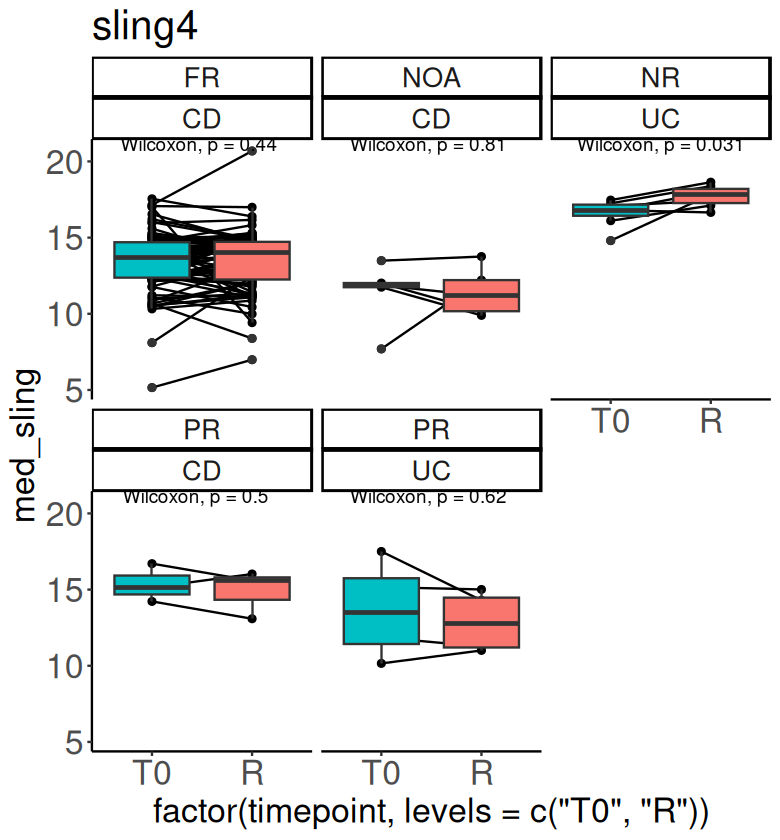

In [71]:
df_p  %>% dplyr::filter(!is.na(sling4) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling4))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa, diagnosis, response, sep = "___"))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient, -diagnosis, -response)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
separate(clone_aa, into = c("patient", "clone_aa", "diagnosis", "response"), sep = "___")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
facet_wrap(~response+diagnosis) +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling4") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling4_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


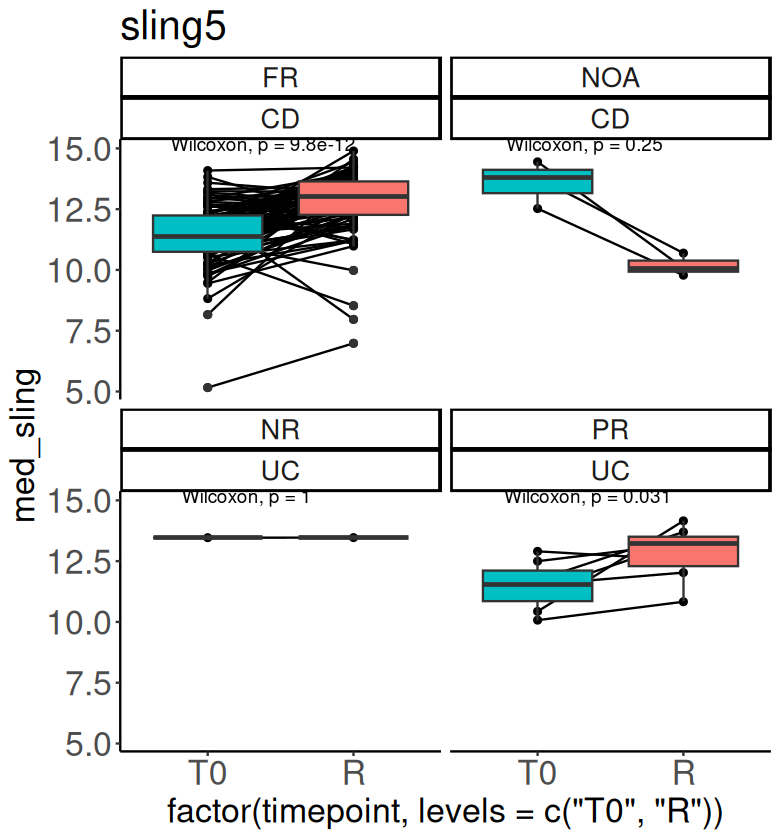

In [72]:
df_p  %>% dplyr::filter(!is.na(sling5) & !grepl(clone_aa, pattern = " NA"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling5))  %>% 
ungroup  %>% 
mutate(clone_aa = paste(patient, clone_aa, diagnosis, response, sep = "___"))  %>% 
pivot_wider(names_from = timepoint, values_from = med_sling)  %>% 
dplyr::select(-R2, -clone_abundance_group2, -clone_ab, -patient, -diagnosis, -response)  %>% 
dplyr::filter(!is.na(T0)&!is.na(R))  %>% 
pivot_longer(!clone_aa, names_to = "timepoint", values_to = "med_sling")  %>% 
separate(clone_aa, into = c("patient", "clone_aa", "diagnosis", "response"), sep = "___")  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = med_sling))  +
geom_point() +
facet_wrap(~response+diagnosis) +
geom_line(aes(group = clone_aa)) +
geom_boxplot(aes(fill = as.factor(timepoint))) +
ggpubr::stat_compare_means(paired = TRUE) +
ggtitle("sling5") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling5_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


### Divided by disease

`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


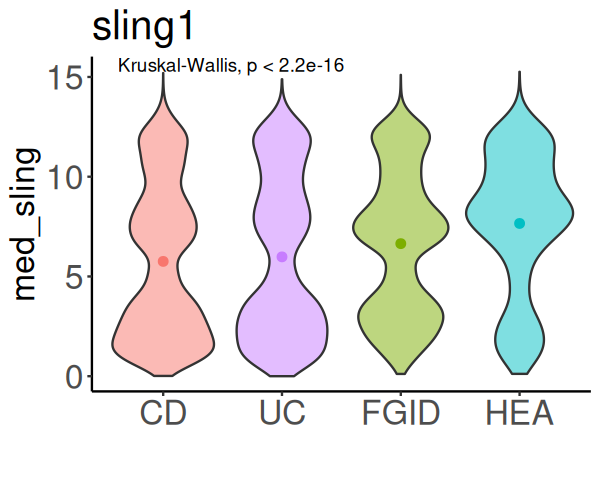

In [130]:
df_p  %>% dplyr::filter(!is.na(sling1) & !grepl(clone_aa, pattern = " NA"))  %>% 
dplyr::filter(diagnosis %in% c("HEA","FGID","CD","UC"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling1))  %>% 
ungroup  %>% 
ggplot(aes(x = reorder(diagnosis, X = med_sling, FUN = median), y = med_sling))  +
xlab("") +
geom_violin(alpha = 0.5, aes(fill = diagnosis)) +
stat_summary(fun = "mean",
               geom = "point", 
               size = 2,
               aes(color = diagnosis)) +
ggpubr::stat_compare_means() +
ggtitle("sling1") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling1_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


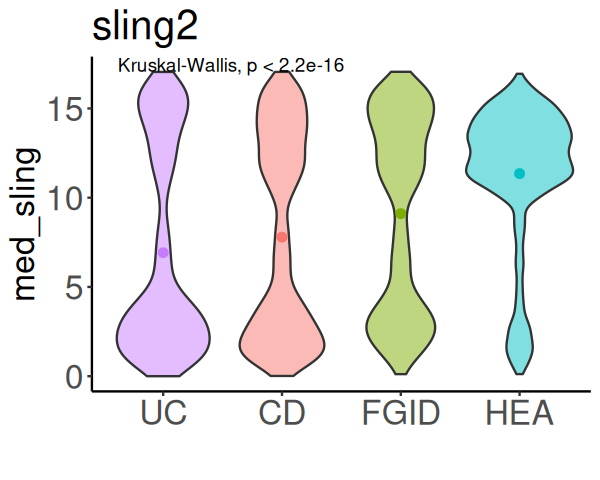

In [129]:
df_p  %>% dplyr::filter(!is.na(sling2) & !grepl(clone_aa, pattern = " NA"))  %>% 
dplyr::filter(diagnosis %in% c("HEA","FGID","CD","UC"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling2))  %>% 
ungroup  %>% 
ggplot(aes(x = reorder(diagnosis, X = med_sling, FUN = median), y = med_sling))  +
xlab("") +
geom_violin(alpha = 0.5, aes(fill = diagnosis)) +
stat_summary(fun = "mean",
               geom = "point", 
               size = 2,
               aes(color = diagnosis)) +
ggpubr::stat_compare_means() +
ggtitle("sling2") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling2_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


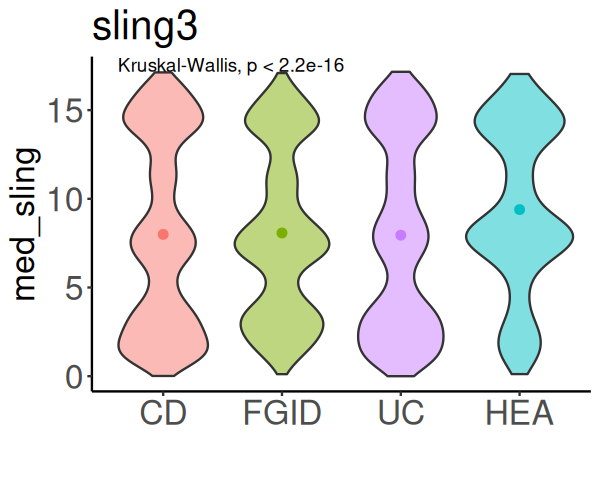

In [131]:
df_p  %>% dplyr::filter(!is.na(sling3) & !grepl(clone_aa, pattern = " NA"))  %>% 
dplyr::filter(diagnosis %in% c("HEA","FGID","CD","UC"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling3))  %>% 
ungroup  %>% 
ggplot(aes(x = reorder(diagnosis, X = med_sling, FUN = median), y = med_sling))  +
xlab("") +
geom_violin(alpha = 0.5, aes(fill = diagnosis)) +
stat_summary(fun = "mean",
               geom = "point", 
               size = 2,
               aes(color = diagnosis)) +
ggpubr::stat_compare_means() +
ggtitle("sling3") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling3_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


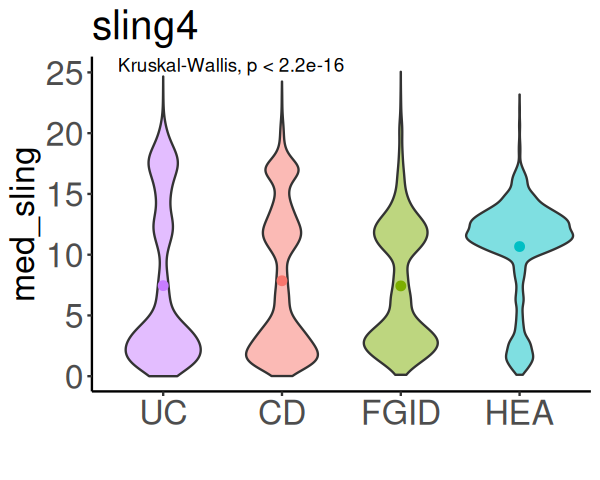

In [132]:
df_p  %>% dplyr::filter(!is.na(sling4) & !grepl(clone_aa, pattern = " NA"))  %>% 
dplyr::filter(diagnosis %in% c("HEA","FGID","CD","UC"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling4))  %>% 
ungroup  %>% 
ggplot(aes(x = reorder(diagnosis, X = med_sling, FUN = median), y = med_sling))  +
xlab("") +
geom_violin(alpha = 0.5, aes(fill = diagnosis)) +
stat_summary(fun = "mean",
               geom = "point", 
               size = 2,
               aes(color = diagnosis)) +
ggpubr::stat_compare_means() +
ggtitle("sling4") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling4_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


`summarise()` has grouped output by 'clone_aa', 'clone_abundance_group2',
'clone_ab', 'timepoint', 'patient', 'diagnosis'. You can override using the
`.groups` argument.


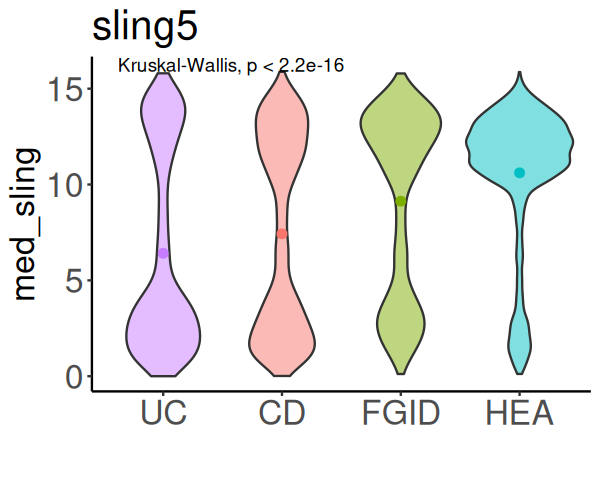

In [133]:
df_p  %>% dplyr::filter(!is.na(sling5) & !grepl(clone_aa, pattern = " NA"))  %>% 
dplyr::filter(diagnosis %in% c("HEA","FGID","CD","UC"))  %>% 
group_by(clone_aa, clone_abundance_group2, clone_ab, timepoint, patient, diagnosis, response)  %>% 
summarise(med_sling = mean(sling5))  %>% 
ungroup  %>% 
ggplot(aes(x = reorder(diagnosis, X = med_sling, FUN = median), y = med_sling))  +
xlab("") +
geom_violin(alpha = 0.5, aes(fill = diagnosis)) +
stat_summary(fun = "mean",
               geom = "point", 
               size = 2,
               aes(color = diagnosis)) +
ggpubr::stat_compare_means() +
ggtitle("sling5") +
theme_classic() +
ggtheme() +
NoLegend()

#ggsave("figures/pseudotime_and_TCR/sling5_T0_R.svg", width = 9, height = 8, units = "cm", create.dir = T)


## Differential progression in pseudotime

In [12]:
library(tradeSeq)
library(condiments)
theme_set(theme_classic())

Registered S3 method overwritten by 'pROC':
  method   from            
  plot.roc spatstat.explore



In [13]:
umap_coord  <- gut_cdn@reductions$umap@cell.embeddings

In [14]:
gut_cdn$umap_1 = unname(umap_coord[,1])

In [15]:
gut_cdn$umap_2 = unname(umap_coord[,2])

In [16]:
df  <- gut_cdn@meta.data  %>% dplyr::select(diagnosis, tissue, layer, 
                                            participant_id,timepoint,  Dim1 = umap_1, Dim2 = umap_2, cl = seurat_clusters)
df_filt  <- df  %>% dplyr::filter(diagnosis %in% c("UC","CD","FGID","HEA"))


In [17]:
scores <- imbalance_score(Object = df_filt %>% select(Dim1, Dim2) %>% as.matrix(),
                          conditions = df_filt$diagnosis)

In [18]:
df_filt$scores <- scores$scores
df_filt$scaled_scores <- scores$scaled_scores

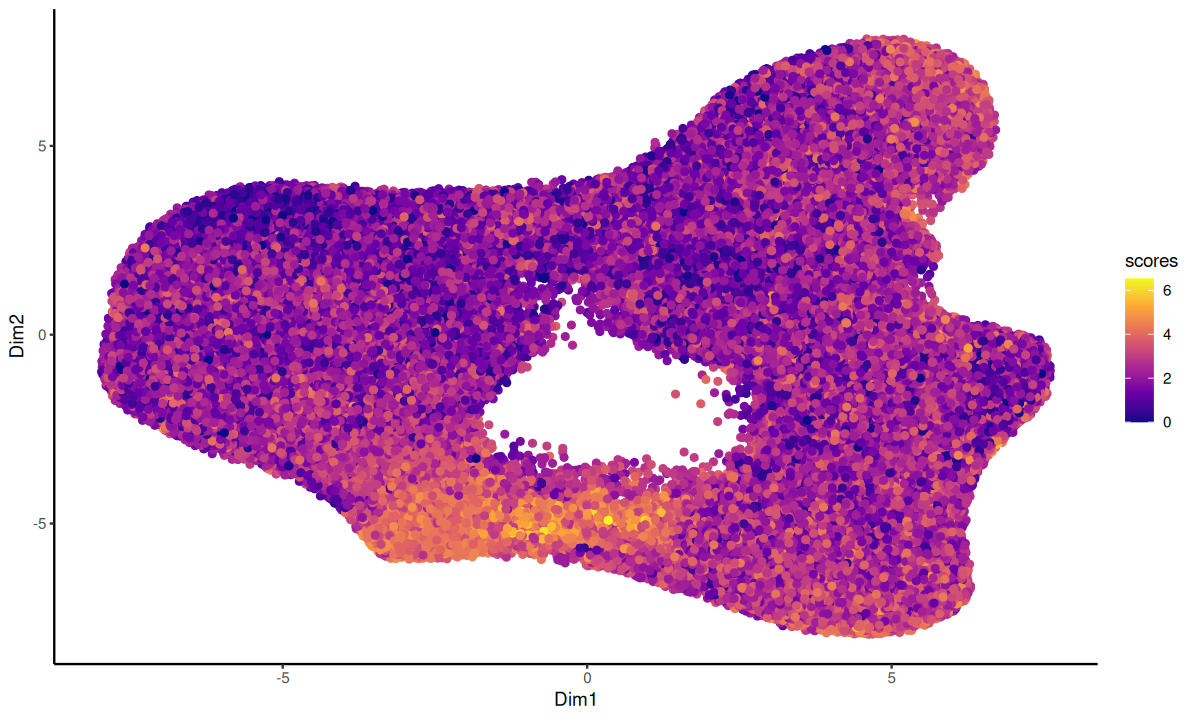

In [221]:
ggplot(df_filt, aes(x = Dim1, y = Dim2, col = scores)) +
  geom_point() +
  scale_color_viridis_c(option = "C")

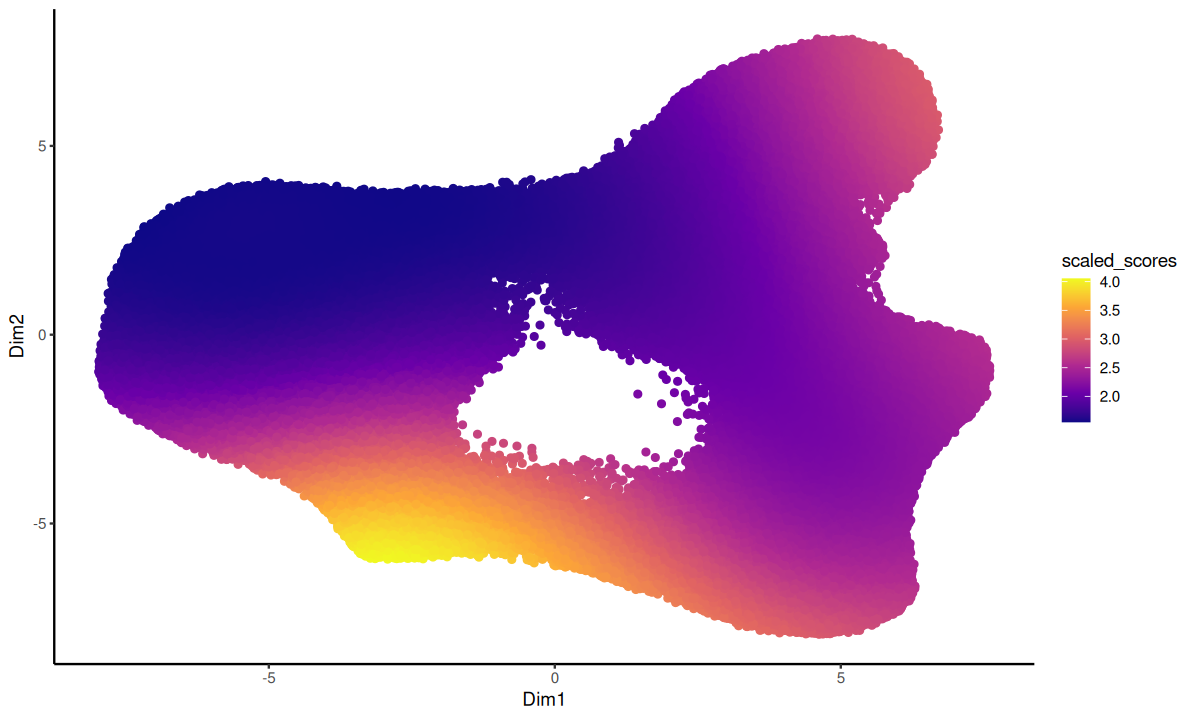

In [222]:
ggplot(df_filt, aes(x = Dim1, y = Dim2, col = scaled_scores)) +
  geom_point() +
  scale_color_viridis_c(option = "C")

In [223]:
pseudotime_test  <- slingPseudotime(sce)

In [224]:
df_filt

,diagnosis,tissue,layer,participant_id,timepoint,Dim1,Dim2,cl,scores,scaled_scores
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<fct>,<dbl>,<dbl[1d]>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,4.4166991,5.49561566,1,1.1605583,2.460343
AAACCTGCAGTCACTA-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,4.2522875,-1.59849209,4,1.1605583,2.088636
AAACCTGCATCGGACC-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,5.1139971,-0.37078244,4,1.7971051,2.211469
AAACCTGTCGCCAGCA-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,2.7365910,0.82743430,3,0.9621532,1.923697
AAACCTGTCGCGATCG-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,4.3603634,5.27745503,1,2.8572559,2.429516
AAACCTGTCTTCGGTC-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,6.0077654,5.97292584,1,2.5478474,2.843922
AAACGGGAGCGTTTAC-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,3.1118924,0.56945919,3,1.5251046,1.969974
AAACGGGCACAGACTT-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,-5.3855017,-2.49158604,7,2.0533707,2.492677
AAACGGGCAGGTGCCT-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,2.3069629,-0.05360401,3,2.4017963,1.933807


In [19]:
df_filt$cells  <- rownames(df_filt)

In [20]:
psts <- slingPseudotime(sce) %>%
  as.data.frame() %>%
  mutate(cells = rownames(.),
         conditions = df$diagnosis) %>%
dplyr::filter(cells %in% df_filt$cells)  %>% 
  pivot_longer(starts_with("Lineage"), values_to = "pseudotime", names_to = "lineages")

In [21]:
psts

cells,conditions,lineages,pseudotime
<chr>,<chr>,<chr>,<dbl>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,FGID,Lineage1,2.4254398
AAACCTGAGAGCCTAG-1_1193610_1_1_1,FGID,Lineage2,2.4049660
AAACCTGAGAGCCTAG-1_1193610_1_1_1,FGID,Lineage3,2.4261019
AAACCTGAGAGCCTAG-1_1193610_1_1_1,FGID,Lineage4,2.4056723
AAACCTGAGAGCCTAG-1_1193610_1_1_1,FGID,Lineage5,2.4060933
AAACCTGCAGTCACTA-1_1193610_1_1_1,FGID,Lineage1,10.3124593
AAACCTGCAGTCACTA-1_1193610_1_1_1,FGID,Lineage2,NA
AAACCTGCAGTCACTA-1_1193610_1_1_1,FGID,Lineage3,10.3373411
AAACCTGCAGTCACTA-1_1193610_1_1_1,FGID,Lineage4,NA


Warning message:
“Removed 996629 rows containing non-finite outside the scale range
(`stat_density()`).”


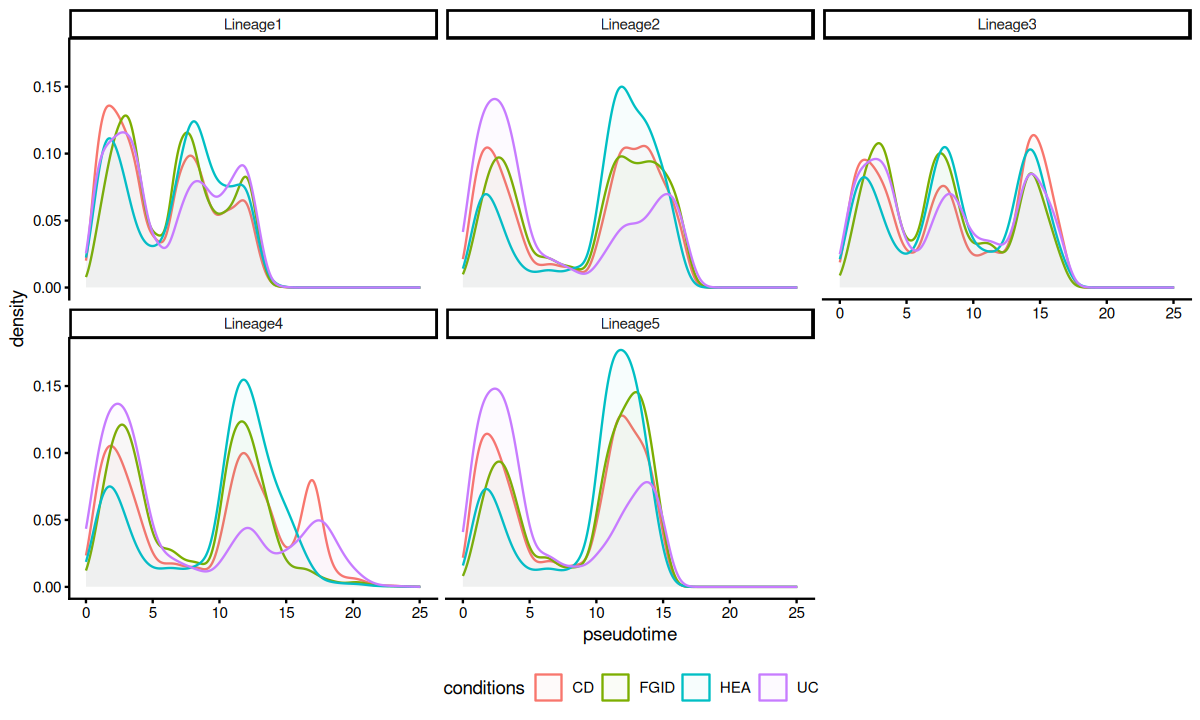

In [22]:
options(repr.plot.width = 10, repr.plot.height = 6)
ggplot(psts, aes(x = pseudotime, color = conditions, fill = conditions)) +
  geom_density(alpha = .03) +
  #scale_fill_brewer(type = "qual") +
  facet_wrap(~lineages) +
  theme(legend.position = "bottom")

In [ ]:
ggsave("figures/pseudotime/diff_progression.svg", width = 10, height = 6)

In [23]:
df$conditions2  <- ifelse(df$diagnosis %in% c("CD","UC"),"IBD","NonIBD")

In [24]:
df

,diagnosis,tissue,layer,participant_id,timepoint,Dim1,Dim2,cl,conditions2
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<fct>,<chr>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,4.4166991,5.49561566,1,NonIBD
AAACCTGCAGTCACTA-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,4.2522875,-1.59849209,4,NonIBD
AAACCTGCATCGGACC-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,5.1139971,-0.37078244,4,NonIBD
AAACCTGTCGCCAGCA-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,2.7365910,0.82743430,3,NonIBD
AAACCTGTCGCGATCG-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,4.3603634,5.27745503,1,NonIBD
AAACCTGTCTTCGGTC-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,6.0077654,5.97292584,1,NonIBD
AAACGGGAGCGTTTAC-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,3.1118924,0.56945919,3,NonIBD
AAACGGGCACAGACTT-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,-5.3855017,-2.49158604,7,NonIBD
AAACGGGCAGGTGCCT-1_1193610_1_1_1,FGID,ILE,LP,001-009,T0,2.3069629,-0.05360401,3,NonIBD


In [25]:
psts$conditions2  <- ifelse(psts$conditions %in% c("CD","UC"),"IBD","NonIBD")

Warning message:
“Removed 996629 rows containing non-finite outside the scale range
(`stat_density()`).”


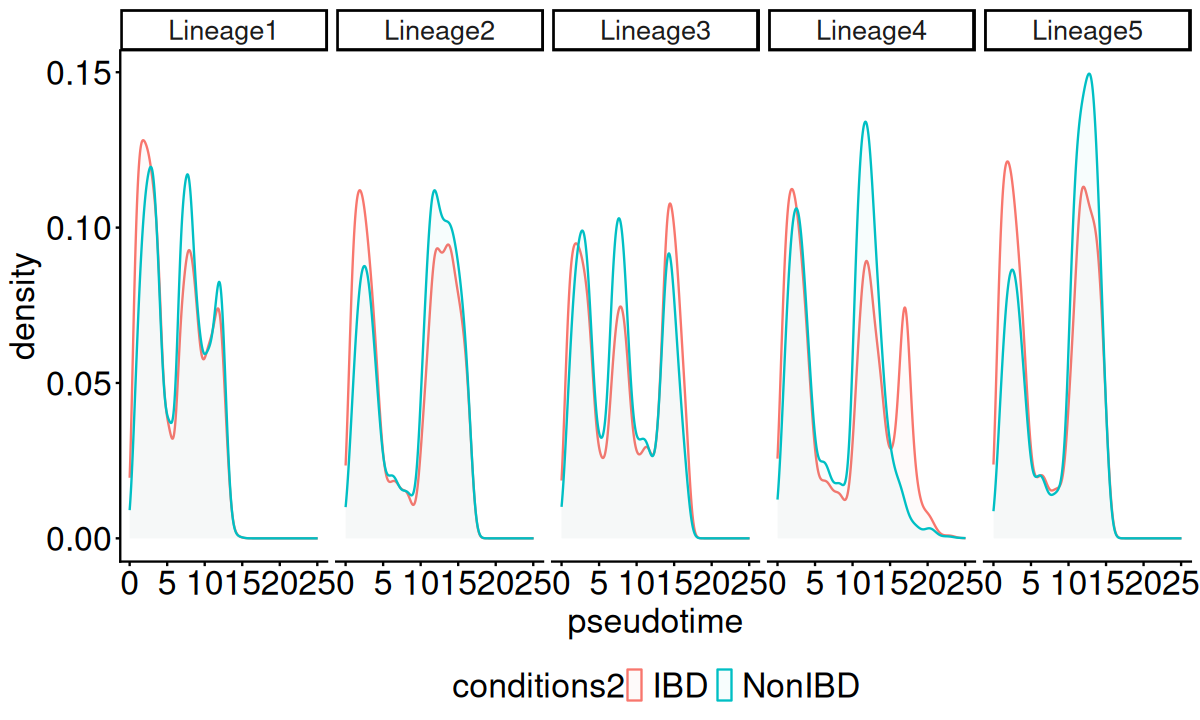

In [58]:
options(repr.plot.width = 10, repr.plot.height = 6)
ggplot(psts, aes(x = pseudotime, color = conditions2, fill = conditions2)) +
  geom_density(alpha = .03) +
  #scale_fill_brewer(type = "qual") +
  facet_wrap(~lineages, ncol = 5) +
  theme(legend.position = "bottom") +ggtheme()

In [61]:
ggsave("figures/pseudotime/diff_progression2.svg", width = 11.5, height = 3.6)

Warning message:
“Removed 996629 rows containing non-finite outside the scale range
(`stat_density()`).”


In [62]:
prog_res <- progressionTest(sce, conditions = df$conditions2, global = TRUE, lineages = TRUE)
knitr::kable(prog_res)



|lineage |  statistic| p.value|
|:-------|----------:|-------:|
|All     | 18.0874268|       0|
|1       |  0.0391991|       0|
|2       |  0.0432430|       0|
|3       |  0.0976446|       0|
|4       |  0.2752034|       0|
|5       |  0.0690622|       0|

In [329]:
set.seed(12)
dif_res <- fateSelectionTest(sce, conditions = df$conditions2, global = FALSE, pairwise = TRUE)

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .



Loading required package: lattice


Attaching package: ‘caret’


The following object is masked from ‘package:purrr’:

    lift




note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .

note: only 1 unique complexity parameters in default grid. Truncating the grid to 1 .



In [331]:
dif_res

pair,statistic,p.value
<chr>,<dbl>,<dbl>
1vs2,0.5183992,5.883551e-16
1vs3,0.5134607,2.889128e-07
1vs4,0.5098644,2.660572e-05
1vs5,0.5302195,5.245708e-40
2vs3,0.5336505,2.976299e-53
2vs4,0.5339929,2.645053e-37
2vs5,0.5245420,7.639185e-27
3vs4,0.5067343,1.895854e-03
3vs5,0.5472214,2.347280e-103


In [316]:
ggsave("figures/pseudotime/diff_progression.svg", width = 10, height = 6)

Warning message:
“Removed 996629 rows containing non-finite outside the scale range
(`stat_density()`).”
